# End-to-End Exploratory Data Analysis

## Online Retail Dataset

This project presents a complete and reproducible Exploratory
Data Analysis of the UCI Online Retail dataset.

### Project Objectives

- Understand the dataset and its business context.
- Assess data quality and investigate unusual observations.
- Explore numerical, categorical, and temporal variables.
- Investigate distributions and relationships.
- Identify meaningful business patterns.
- Communicate findings, limitations, and uncertainty.

### Observational Unit

Each row represents an invoice line item, not necessarily
an entire invoice or a unique customer.

### Data Source

UCI Machine Learning Repository — Online Retail

https://archive.ics.uci.edu/dataset/352/online+retail

## 1. Project Setup

Import the required libraries, locate the project directory,
define project paths, and prepare the output directories.

The notebook uses the project's local Python environment
managed by uv.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns

from scipy import stats
from IPython.display import display
from matplotlib.figure import Figure
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")


# --------------------------------------------------
# 1. Locate the project root
# --------------------------------------------------

def find_project_root(start: Path) -> Path:
    """
    Find the project root by locating pyproject.toml.
    """

    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )


PROJECT_ROOT = find_project_root(Path.cwd())


# --------------------------------------------------
# 2. Define project paths
# --------------------------------------------------

DATA_DIR = PROJECT_ROOT / "data"

RAW_DATA_DIR = DATA_DIR / "raw"
INTERIM_DATA_DIR = DATA_DIR / "interim"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
PROFILING_DIR = OUTPUT_DIR / "profiling"

REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

SOURCE_DIR = PROJECT_ROOT / "src"
CONFIG_DIR = PROJECT_ROOT / "config"
LOG_DIR = PROJECT_ROOT / "logs"


# --------------------------------------------------
# 3. Define dataset information
# --------------------------------------------------

DATASET_NAME = "Online Retail"

RAW_DATA_PATH = RAW_DATA_DIR / "Online Retail.xlsx"

DATASET_SHA256 = (
    "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d"
)


# --------------------------------------------------
# 4. Create required output directories
# --------------------------------------------------

OUTPUT_DIRECTORIES = [
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    TABLE_DIR,
    PROFILING_DIR,
    FIGURE_DIR,
    LOG_DIR,
]

for directory in OUTPUT_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 5. Verify the project environment and raw data
# --------------------------------------------------

if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Raw dataset not found: {RAW_DATA_PATH}"
    )


print("Project setup completed successfully.")
print("-" * 50)
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset      : {DATASET_NAME}")
print(f"Dataset path : {RAW_DATA_PATH}")
print(f"Dataset size : {RAW_DATA_PATH.stat().st_size:,} bytes")
print("-" * 50)

Project setup completed successfully.
--------------------------------------------------
Project root : d:\coding\eda\Part IX - Capstone
Dataset      : Online Retail
Dataset path : d:\coding\eda\Part IX - Capstone\data\raw\Online Retail.xlsx
Dataset size : 23,715,344 bytes
--------------------------------------------------


## 2. Visualization Convention

This project uses Matplotlib's object-oriented API exclusively.

Figures are created using matplotlib.figure.Figure, and Axes
are obtained through the Figure's subplots() method.

IPython's display() function is used to publish figures
immediately at the point of execution.

The pyplot API is not used anywhere in this project.

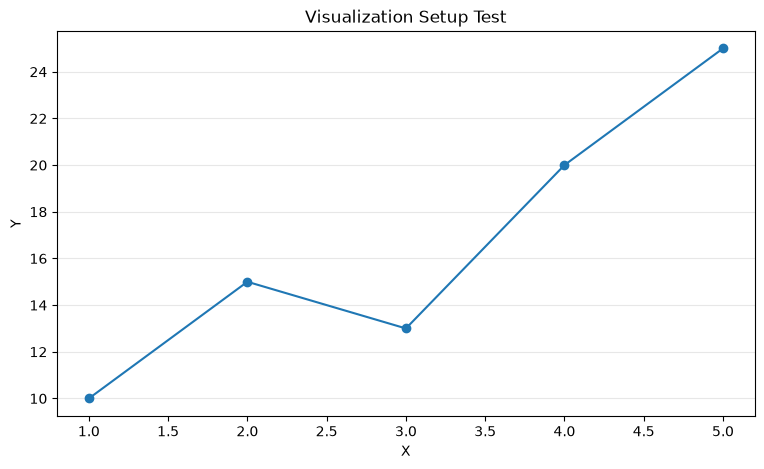

The next Python statement has executed.


In [2]:
fig = Figure(figsize=(9, 5))

ax = fig.subplots()

ax.plot(
    [1, 2, 3, 4, 5],
    [10, 15, 13, 20, 25],
    marker="o",
)

ax.set_title("Visualization Setup Test")
ax.set_xlabel("X")
ax.set_ylabel("Y")

ax.grid(axis="y", alpha=0.3)

# Render synchronously
fig.canvas.draw()

# Display immediately
display(fig)

print("The next Python statement has executed.")

## 3. Data Acquisition and Initial Inspection

Before conducting any analysis, we must establish that the
correct dataset has been acquired and loaded successfully.

This section covers:

1. Verifying the integrity of the original dataset.
2. Loading the Excel workbook into Pandas.
3. Inspecting its structure and dimensions.
4. Examining variable names and data types.
5. Reviewing initial observations.

The original dataset will remain unchanged. Any cleaning,
transformation, or derived data will be handled separately.

### 3.1 Data Integrity Verification

We use a SHA-256 checksum to verify that the local dataset
matches the file fingerprint recorded during acquisition.

This helps detect accidental modifications to the original
workbook.

In [3]:
import hashlib


def calculate_sha256(file_path: Path) -> str:
    """Calculate the SHA-256 checksum of a file."""

    sha256 = hashlib.sha256()

    with file_path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


actual_sha256 = calculate_sha256(RAW_DATA_PATH)

print("Expected SHA-256:", DATASET_SHA256)
print("Actual SHA-256:  ", actual_sha256)

if actual_sha256 != DATASET_SHA256:
    raise ValueError(
        "Dataset integrity verification failed. "
        "The original dataset may have been modified."
    )

print("\nDataset integrity verified successfully.")


Expected SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Actual SHA-256:   43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d

Dataset integrity verified successfully.


### 3.2 Loading the Dataset

We will load the original Excel workbook using Pandas.

Identifier columns will initially be represented as strings.
Identifiers are labels, not numerical measurements, even when
their values contain digits.

We will not perform any cleaning at this stage.

In [4]:
df = pd.read_excel(
    RAW_DATA_PATH,
    sheet_name="Online Retail",
    engine="openpyxl",
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string",
    },
)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")


Dataset loaded successfully.
Shape: 541,909 rows × 8 columns


### 3.3 Structural Inspection

We begin with a structural overview before examining individual
variables or calculating statistics.

The inspection includes:

- Dataset dimensions.
- Column names.
- Data types.
- Non-null counts.
- Memory usage.

In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
display(pd.Index(df.columns))

print("\nDataFrame information:")
df.info(memory_usage="deep")


Dataset shape: (541909, 8)

Column names:


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(1), string(3)
memory usage: 82.6 MB


### 3.4 Initial Observations

We inspect a few records to understand how observations are
represented.

At this stage, we are looking for structural clues, not making
conclusions about the dataset.

In [6]:
print("First five observations:")
display(df.head())

print("Last five observations:")
display(df.tail())

print("Five randomly selected observations:")
display(df.sample(n=5, random_state=42))

First five observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Last five observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


Five randomly selected observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502,United Kingdom


### 3.5 Variable Inventory

A variable inventory provides an initial overview of the
dataset's columns, their data types, and their non-null counts.

We will extend this inventory later with semantic types,
missingness percentages, uniqueness, and quality assessments.

In [7]:
variable_inventory = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "missing_percentage": (
        df.isna().mean().mul(100).values
    ),
    "unique_count": df.nunique(dropna=True).values,
})

variable_inventory = variable_inventory.sort_values(
    "missing_percentage",
    ascending=False,
    ignore_index=True,
)

display(variable_inventory)

,column,dtype,non_null_count,missing_count,missing_percentage,unique_count
0,CustomerID,string,406829,135080,24.926694,4372
1,Description,object,540455,1454,0.268311,4223
2,StockCode,string,541909,0,0.000000,4070
3,InvoiceNo,string,541909,0,0.000000,25900
4,Quantity,int64,541909,0,0.000000,722
5,InvoiceDate,datetime64[us],541909,0,0.000000,23260
6,UnitPrice,float64,541909,0,0.000000,1630
7,Country,str,541909,0,0.000000,38


In [8]:
inventory_path = TABLE_DIR / "initial_variable_inventory.csv"

variable_inventory.to_csv(
    inventory_path,
    index=False,
)

print("Variable inventory saved to:")
print(inventory_path)

Variable inventory saved to:
d:\coding\eda\Part IX - Capstone\outputs\tables\initial_variable_inventory.csv


## 4. Data Quality Assessment

Before conducting detailed exploratory analysis, we need to evaluate the
reliability and consistency of the dataset.

Data quality issues can distort statistical summaries, visualizations,
and business interpretations. Therefore, this section investigates
duplicate records, missing values, unusual numerical values, transaction
anomalies, temporal validity, and categorical inconsistencies.

The original dataset will remain unchanged throughout this investigation.
All identified issues will be documented before deciding how they should
be handled in subsequent analyses.

### 4.1 Duplicate Records

Duplicate records may inflate transaction counts, quantities, and
transaction values.

We will investigate both:

- **Exact duplicate rows:** Records where every column has an identical
  value.
- **Potential transaction-line duplicates:** Records sharing the same
  invoice number, stock code, description, quantity, unit price,
  customer, and invoice date.

An exact duplicate is not automatically proof of an erroneous record.
We must consider the dataset's observational unit and transaction
structure before deciding how to handle duplicates.

In [9]:
exact_duplicate_mask = df.duplicated(keep=False)
exact_duplicate_count = df.duplicated().sum()

print(f"Total records: {len(df):,}")
print(f"Exact duplicate rows beyond first occurrences: {exact_duplicate_count:,}")
print(f"Records involved in duplicate groups: {exact_duplicate_mask.sum():,}")

if exact_duplicate_count > 0:
    print("\nSample duplicate records:")
    display(
        df.loc[exact_duplicate_mask]
        .sort_values(by=df.columns.tolist())
        .head(10)
    )

Total records: 541,909
Exact duplicate rows beyond first occurrences: 5,268
Records involved in duplicate groups: 10,147

Sample duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom


### 4.2 Missing Values

Missing values can reduce the usable sample size and introduce bias,
particularly when their occurrence is not random.

We will examine:

- Missing-value counts and percentages.
- Missingness patterns across variables.
- Whether records with missing customer identifiers still contain
  useful transaction information.

Missing values will not be automatically removed. Their treatment
depends on the analytical question and the role of each variable.

In [10]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100),
    "non_missing_count": df.notna().sum(),
})

missing_summary = (
    missing_summary
    .sort_values("missing_percentage", ascending=False)
    .reset_index(names="column")
)

display(missing_summary)

,column,missing_count,missing_percentage,non_missing_count
0,CustomerID,135080,24.926694,406829
1,Description,1454,0.268311,540455
2,StockCode,0,0.000000,541909
3,InvoiceNo,0,0.000000,541909
4,Quantity,0,0.000000,541909
5,InvoiceDate,0,0.000000,541909
6,UnitPrice,0,0.000000,541909
7,Country,0,0.000000,541909


In [11]:
missing_patterns = (
    df.isna()
    .value_counts()
    .rename("record_count")
    .reset_index()
)

missing_patterns["percentage"] = (
    missing_patterns["record_count"] / len(df) * 100
)

display(missing_patterns)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,record_count,percentage
0,False,False,False,False,False,False,False,False,406829,75.073306
1,False,False,False,False,False,False,True,False,133626,24.658384
2,False,False,True,False,False,False,True,False,1454,0.268311


### 4.3 Distribution of Duplicate Records

We have identified exact duplicate records, but we do not yet know
whether they are distributed uniformly or concentrated in particular
invoices.

We will examine the invoices containing the largest numbers of records
involved in exact-duplicate groups.

This helps us understand the scale and structure of the duplication
without prematurely deleting records.

In [12]:
duplicate_invoice_summary = (
    df.loc[exact_duplicate_mask]
    .groupby("InvoiceNo")
    .agg(
        records_in_duplicate_groups=("InvoiceNo", "size"),
        distinct_stock_codes=("StockCode", "nunique"),
        distinct_customers=("CustomerID", "nunique"),
    )
    .sort_values("records_in_duplicate_groups", ascending=False)
    .reset_index()
)

print(
    "Invoices containing records involved in exact-duplicate groups:",
    f"{duplicate_invoice_summary.shape[0]:,}",
)

print("\nTop 10 invoices by records involved in duplicate groups:")
display(duplicate_invoice_summary.head(10))

Invoices containing records involved in exact-duplicate groups: 1,933

Top 10 invoices by records involved in duplicate groups:


,InvoiceNo,records_in_duplicate_groups,distinct_stock_codes,distinct_customers
0,547651,57,26,1
1,579458,53,25,1
2,577482,52,26,1
3,572103,50,23,1
4,574481,49,22,1
5,552285,48,24,1
6,537781,47,22,1
7,555524,40,6,1
8,575117,40,19,1
9,569897,40,19,1


In [13]:
missing_description = df.loc[df["Description"].isna()].copy()

print(f"Records with missing descriptions: {len(missing_description):,}")
print(
    "Distinct stock codes among these records:",
    missing_description["StockCode"].nunique(),
)
print(
    "Distinct invoices among these records:",
    missing_description["InvoiceNo"].nunique(),
)

print("\nSample records with missing descriptions:")
display(missing_description.head(10))

print("\nMost frequent stock codes with missing descriptions:")
display(
    missing_description["StockCode"]
    .value_counts()
    .head(15)
    .rename_axis("StockCode")
    .reset_index(name="record_count")
)

Records with missing descriptions: 1,454
Distinct stock codes among these records: 960
Distinct invoices among these records: 1454

Sample records with missing descriptions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom



Most frequent stock codes with missing descriptions:


,StockCode,record_count
0,35965,10
1,23084,10
2,22084,9
3,22451,6
4,21784,5
5,22501,5
6,22866,5
7,23348,5
8,21067,5
9,21033,5


This (above) will help determine whether missing descriptions are isolated incidents or concentrated around particular stock codes.

### 4.4 Numerical Validity and Unusual Values

The dataset contains two numerical transaction variables:

- `Quantity`: Number of units recorded on an invoice line.
- `UnitPrice`: Recorded price per unit.

We need to investigate:

- Zero and negative quantities.
- Zero and negative unit prices.
- Extremely large positive or negative quantities.
- Extremely high unit prices.

Negative quantities may represent returns or credit adjustments.
Zero-price records may represent samples, adjustments, or other
special transaction types.

These values are not automatically errors. Their business meaning
must be investigated before any exclusion or transformation.

In [14]:
numerical_summary = (
    df[["Quantity", "UnitPrice"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

display(numerical_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0


In [15]:
numerical_quality = pd.DataFrame({
    "condition": [
        "Quantity equals zero",
        "Quantity below zero",
        "Quantity above zero",
        "UnitPrice equals zero",
        "UnitPrice below zero",
        "UnitPrice above zero",
    ],
    "record_count": [
        df["Quantity"].eq(0).sum(),
        df["Quantity"].lt(0).sum(),
        df["Quantity"].gt(0).sum(),
        df["UnitPrice"].eq(0).sum(),
        df["UnitPrice"].lt(0).sum(),
        df["UnitPrice"].gt(0).sum(),
    ],
})

numerical_quality["percentage"] = (
    numerical_quality["record_count"] / len(df) * 100
)

display(numerical_quality)

,condition,record_count,percentage
0,Quantity equals zero,0,0.000000
1,Quantity below zero,10624,1.960477
2,Quantity above zero,531285,98.039523
3,UnitPrice equals zero,2515,0.464100
4,UnitPrice below zero,2,0.000369
5,UnitPrice above zero,539392,99.535531


In [16]:
print("10 largest positive quantities:")
display(
    df.nlargest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

print("\n10 smallest quantities:")
display(
    df.nsmallest(10, "Quantity")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

print("\n10 highest unit prices:")
display(
    df.nlargest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

print("\n10 lowest unit prices:")
display(
    df.nsmallest(10, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate", "Country"]
    ]
)

10 largest positive quantities:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
540421,581483,23843,80995,2.08,2011-12-09 09:15:00,United Kingdom
61619,541431,23166,74215,1.04,2011-01-18 10:01:00,United Kingdom
502122,578841,84826,12540,0.00,2011-11-25 15:57:00,United Kingdom
74614,542504,37413,5568,0.00,2011-01-28 12:03:00,United Kingdom
421632,573008,84077,4800,0.21,2011-10-27 12:26:00,United Kingdom
206121,554868,22197,4300,0.72,2011-05-27 10:52:00,United Kingdom
220843,556231,85123A,4000,0.00,2011-06-09 15:04:00,United Kingdom
97432,544612,22053,3906,0.82,2011-02-22 10:43:00,United Kingdom
270885,560599,18007,3186,0.06,2011-07-19 17:04:00,United Kingdom
52711,540815,21108,3114,2.10,2011-01-11 12:55:00,United Kingdom



10 smallest quantities:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
540422,C581484,23843,-80995,2.08,2011-12-09 09:27:00,United Kingdom
61624,C541433,23166,-74215,1.04,2011-01-18 10:17:00,United Kingdom
225529,556690,23005,-9600,0.00,2011-06-14 10:37:00,United Kingdom
225530,556691,23005,-9600,0.00,2011-06-14 10:37:00,United Kingdom
4287,C536757,84347,-9360,0.03,2010-12-02 14:23:00,United Kingdom
225528,556687,23003,-9058,0.00,2011-06-14 10:36:00,United Kingdom
115818,546152,72140F,-5368,0.00,2011-03-09 17:25:00,United Kingdom
431381,573596,79323W,-4830,0.00,2011-10-31 15:17:00,United Kingdom
341601,566768,16045,-3667,0.00,2011-09-14 17:53:00,United Kingdom
323458,565304,16259,-3167,0.00,2011-09-02 12:18:00,United Kingdom



10 highest unit prices:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
222681,C556445,M,-1,38970.00,2011-06-10 15:31:00,United Kingdom
524602,C580605,AMAZONFEE,-1,17836.46,2011-12-05 11:36:00,United Kingdom
43702,C540117,AMAZONFEE,-1,16888.02,2011-01-05 09:55:00,United Kingdom
43703,C540118,AMAZONFEE,-1,16453.71,2011-01-05 09:57:00,United Kingdom
15016,C537630,AMAZONFEE,-1,13541.33,2010-12-07 15:04:00,United Kingdom
15017,537632,AMAZONFEE,1,13541.33,2010-12-07 15:08:00,United Kingdom
16356,C537651,AMAZONFEE,-1,13541.33,2010-12-07 15:49:00,United Kingdom
16232,C537644,AMAZONFEE,-1,13474.79,2010-12-07 15:34:00,United Kingdom
524601,C580604,AMAZONFEE,-1,11586.50,2011-12-05 11:35:00,United Kingdom
299982,A563185,B,1,11062.06,2011-08-12 14:50:00,United Kingdom



10 lowest unit prices:


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Country
299983,A563186,B,1,-11062.06,2011-08-12 14:51:00,United Kingdom
299984,A563187,B,1,-11062.06,2011-08-12 14:52:00,United Kingdom
622,536414,22139,56,0.00,2010-12-01 11:52:00,United Kingdom
1970,536545,21134,1,0.00,2010-12-01 14:32:00,United Kingdom
1971,536546,22145,1,0.00,2010-12-01 14:33:00,United Kingdom
1972,536547,37509,1,0.00,2010-12-01 14:33:00,United Kingdom
1987,536549,85226A,1,0.00,2010-12-01 14:34:00,United Kingdom
1988,536550,85044,1,0.00,2010-12-01 14:34:00,United Kingdom
2024,536552,20950,1,0.00,2010-12-01 14:34:00,United Kingdom
2025,536553,37461,3,0.00,2010-12-01 14:35:00,United Kingdom


### 4.5 Invoice Types and Cancellation Patterns

Invoice numbers may contain prefixes that distinguish ordinary
transactions from cancellations or other special records.

We will investigate invoice-number patterns and compare them with
quantity signs.

In particular, we will examine whether invoices beginning with
"C" are associated with negative quantities.

This is an exploratory classification based on the recorded invoice
identifiers, not an assumption that every negative quantity must
belong to a cancellation.

In [17]:
df["InvoicePrefix"] = (
    df["InvoiceNo"]
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .fillna("Numeric")
    .str.upper()
)

invoice_prefix_summary = (
    df.groupby("InvoicePrefix")
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        negative_quantity_records=("Quantity", lambda s: s.lt(0).sum()),
        positive_quantity_records=("Quantity", lambda s: s.gt(0).sum()),
        zero_quantity_records=("Quantity", lambda s: s.eq(0).sum()),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

invoice_prefix_summary["record_percentage"] = (
    invoice_prefix_summary["record_count"] / len(df) * 100
)

display(invoice_prefix_summary)

,InvoicePrefix,record_count,unique_invoices,negative_quantity_records,positive_quantity_records,zero_quantity_records,record_percentage
0,NUMERIC,532618,22061,1336,531282,0,98.285506
1,C,9288,3836,9288,0,0,1.713941
2,A,3,3,0,3,0,0.000554


In [18]:
quantity_invoice_relationship = pd.crosstab(
    df["InvoicePrefix"],
    pd.cut(
        df["Quantity"],
        bins=[-np.inf, 0, np.inf],
        labels=["Non-positive", "Positive"],
    ),
    margins=True,
)

display(quantity_invoice_relationship)

Quantity,Non-positive,Positive,All
InvoicePrefix,,,
A,0,3,3
C,9288,0,9288
NUMERIC,1336,531282,532618
All,10624,531285,541909


In [19]:
special_stock_codes = (
    df.groupby("StockCode")
    .agg(
        record_count=("StockCode", "size"),
        descriptions=("Description", lambda s: ", ".join(
            sorted(s.dropna().astype(str).unique())[:5]
        )),
        total_quantity=("Quantity", "sum"),
        minimum_unit_price=("UnitPrice", "min"),
        maximum_unit_price=("UnitPrice", "max"),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

print("Stock codes with non-numeric or special-looking identifiers:")
display(
    special_stock_codes.loc[
        special_stock_codes["StockCode"].str.contains(
            r"[A-Za-z]", regex=True, na=False
        )
    ].sort_values("record_count", ascending=False).head(30)
)

Stock codes with non-numeric or special-looking identifiers:


,StockCode,record_count,descriptions,total_quantity,minimum_unit_price,maximum_unit_price
0,85123A,2313,"?, CREAM HANGING HEART T-LIGHT HOLDER, WHITE H...",38830,0.00,5.91
2,85099B,2159,JUMBO BAG RED RETROSPOT,47363,0.00,4.95
13,POST,1256,POSTAGE,6353,0.00,8142.75
45,85099C,960,JUMBO BAG BAROQUE BLACK WHITE,13641,1.65,4.21
48,82494L,943,"WOODEN FRAME ANTIQUE WHITE , cracked, crushed ctn",6308,0.00,7.62
68,85099F,842,JUMBO BAG STRAWBERRY,16035,0.00,4.95
94,DOT,710,DOTCOM POSTAGE,1707,0.00,4505.17
156,M,571,Manual,3164,0.00,38970.00
168,84970S,546,HANGING HEART ZINC T-LIGHT HOLDER,8880,0.64,2.13
172,84596B,541,SMALL DOLLY MIX DESIGN ORANGE BOWL,5062,0.42,2.51


In [20]:
negative_price_records = df.loc[
    df["UnitPrice"].lt(0),
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country",
    ],
]

print(f"Records with negative unit prices: {len(negative_price_records):,}")
display(negative_price_records)

Records with negative unit prices: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom


In [21]:
zero_price_summary = (
    df.loc[df["UnitPrice"].eq(0)]
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        record_count=("InvoiceNo", "size"),
        positive_quantity=("Quantity", lambda s: s.gt(0).sum()),
        negative_quantity=("Quantity", lambda s: s.lt(0).sum()),
        total_quantity=("Quantity", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

display(zero_price_summary.head(25))

,StockCode,Description,record_count,positive_quantity,negative_quantity,total_quantity
0,35965,NaN,10,9,1,38
1,23084,NaN,10,8,2,332
2,22676,FRENCH BLUE METAL DOOR SIGN 1,9,9,0,26
3,22084,NaN,9,7,2,-129
4,22683,FRENCH BLUE METAL DOOR SIGN 8,8,8,0,19
5,22686,FRENCH BLUE METAL DOOR SIGN No,7,7,0,26
6,22678,FRENCH BLUE METAL DOOR SIGN 3,7,7,0,21
7,22679,FRENCH BLUE METAL DOOR SIGN 4,7,7,0,21
8,22666,RECIPE BOX PANTRY YELLOW DESIGN,7,7,0,21
9,21116,OWL DOORSTOP,7,7,0,12


In [22]:
temporal_summary = pd.DataFrame({
    "metric": [
        "Earliest invoice date",
        "Latest invoice date",
        "Unique invoice timestamps",
        "Records in 2010",
        "Records in 2011",
        "Records outside 2010–2011",
        "Weekend records",
        "Weekday records",
    ],
    "value": [
        df["InvoiceDate"].min(),
        df["InvoiceDate"].max(),
        df["InvoiceDate"].nunique(),
        df["InvoiceDate"].dt.year.eq(2010).sum(),
        df["InvoiceDate"].dt.year.eq(2011).sum(),
        (~df["InvoiceDate"].dt.year.isin([2010, 2011])).sum(),
        df["InvoiceDate"].dt.day_of_week.ge(5).sum(),
        df["InvoiceDate"].dt.day_of_week.lt(5).sum(),
    ],
})

display(temporal_summary)

,metric,value
0,Earliest invoice date,2010-12-01 08:26:00
1,Latest invoice date,2011-12-09 12:50:00
2,Unique invoice timestamps,23260
3,Records in 2010,42481
4,Records in 2011,499428
5,Records outside 2010–2011,0
6,Weekend records,64375
7,Weekday records,477534


In [23]:
categorical_columns = ["Country", "StockCode", "InvoiceNo"]

categorical_summary = pd.DataFrame({
    "column": categorical_columns,
    "unique_values": [df[col].nunique(dropna=True) for col in categorical_columns],
    "leading_or_trailing_whitespace": [
        df[col].dropna().astype(str).ne(
            df[col].dropna().astype(str).str.strip()
        ).sum()
        for col in categorical_columns
    ],
})

display(categorical_summary)

print("Country values:")
display(
    df["Country"]
    .value_counts(dropna=False)
    .rename_axis("Country")
    .reset_index(name="record_count")
)

,column,unique_values,leading_or_trailing_whitespace
0,Country,38,0
1,StockCode,4070,0
2,InvoiceNo,25900,0


Country values:


,Country,record_count
0,United Kingdom,495478
1,Germany,9495
2,France,8557
3,EIRE,8196
4,Spain,2533
5,Netherlands,2371
6,Belgium,2069
7,Switzerland,2002
8,Portugal,1519
9,Australia,1259


In [24]:
non_numeric_invoice_records = df.loc[
    df["InvoicePrefix"].ne("NUMERIC"),
    ["InvoiceNo", "InvoicePrefix", "Quantity", "UnitPrice", "Description"],
]

print("Non-numeric invoice prefixes:")
display(
    non_numeric_invoice_records
    .drop_duplicates()
    .sort_values(["InvoicePrefix", "InvoiceNo"])
    .head(30)
)

print("\nRecords by invoice prefix:")
display(
    non_numeric_invoice_records
    .groupby("InvoicePrefix")
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        negative_quantities=("Quantity", lambda s: s.lt(0).sum()),
        zero_quantities=("Quantity", lambda s: s.eq(0).sum()),
        positive_quantities=("Quantity", lambda s: s.gt(0).sum()),
    )
)

Non-numeric invoice prefixes:


,InvoiceNo,InvoicePrefix,Quantity,UnitPrice,Description
299982,A563185,A,1,11062.06,Adjust bad debt
299983,A563186,A,1,-11062.06,Adjust bad debt
299984,A563187,A,1,-11062.06,Adjust bad debt
141,C536379,C,-1,27.50,Discount
154,C536383,C,-1,4.65,SET OF 3 COLOURED FLYING DUCKS
235,C536391,C,-12,1.65,PLASTERS IN TIN CIRCUS PARADE
236,C536391,C,-24,0.29,PACK OF 12 PINK PAISLEY TISSUES
237,C536391,C,-24,0.29,PACK OF 12 BLUE PAISLEY TISSUES
238,C536391,C,-24,0.29,PACK OF 12 RED RETROSPOT TISSUES
239,C536391,C,-12,3.45,CHICK GREY HOT WATER BOTTLE



Records by invoice prefix:


,record_count,unique_invoices,negative_quantities,zero_quantities,positive_quantities
InvoicePrefix,,,,,
A,3,3,0,0,3
C,9288,3836,9288,0,0


In [25]:
df["QuantitySign"] = np.select(
    [
        df["Quantity"].lt(0),
        df["Quantity"].eq(0),
        df["Quantity"].gt(0),
    ],
    [
        "Negative",
        "Zero",
        "Positive",
    ],
    default="Unknown",
)

quantity_sign_by_prefix = pd.crosstab(
    df["InvoicePrefix"],
    df["QuantitySign"],
    margins=True,
)

display(quantity_sign_by_prefix)

print("\nRecords with A-prefixed invoice numbers:")
display(
    df.loc[
        df["InvoicePrefix"].eq("A"),
        ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
    ]
)

QuantitySign,Negative,Positive,All
InvoicePrefix,,,
A,0,3,3
C,9288,0,9288
NUMERIC,1336,531282,532618
All,10624,531285,541909



Records with A-prefixed invoice numbers:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
299982,A563185,B,Adjust bad debt,1,11062.06
299983,A563186,B,Adjust bad debt,1,-11062.06
299984,A563187,B,Adjust bad debt,1,-11062.06


In [26]:
zero_price_records = df.loc[df["UnitPrice"].eq(0)].copy()

print(f"Zero-price records: {len(zero_price_records):,}")
print(
    "Distinct stock codes:",
    zero_price_records["StockCode"].nunique(),
)
print(
    "Distinct invoice numbers:",
    zero_price_records["InvoiceNo"].nunique(),
)

print("\nMost frequent zero-price stock codes:")
display(
    zero_price_records["StockCode"]
    .value_counts()
    .head(20)
    .rename_axis("StockCode")
    .reset_index(name="record_count")
)

print("\nDescriptions associated with zero-price records:")
display(
    zero_price_records["Description"]
    .value_counts(dropna=False)
    .head(20)
    .rename_axis("Description")
    .reset_index(name="record_count")
)

Zero-price records: 2,515
Distinct stock codes: 1419
Distinct invoice numbers: 2155

Most frequent zero-price stock codes:


,StockCode,record_count
0,23084,16
1,35965,13
2,20713,11
3,22501,10
4,22676,9
5,22627,9
6,22084,9
7,22683,8
8,21116,8
9,46000S,8



Descriptions associated with zero-price records:


,Description,record_count
0,NaN,1454
1,check,159
2,?,47
3,damages,45
4,damaged,43
5,found,25
6,sold as set on dotcom,20
7,adjustment,16
8,Damaged,14
9,FRENCH BLUE METAL DOOR SIGN 1,9


In [27]:
financial_adjustments = df.loc[
    df["StockCode"].isin(["B", "M", "AMAZONFEE", "POST", "DOT"])
].copy()

adjustment_summary = (
    financial_adjustments
    .groupby("StockCode", dropna=False)
    .agg(
        record_count=("InvoiceNo", "size"),
        descriptions=("Description", lambda s: ", ".join(
            sorted(s.dropna().astype(str).unique())
        )),
        negative_quantity_records=("Quantity", lambda s: s.lt(0).sum()),
        negative_price_records=("UnitPrice", lambda s: s.lt(0).sum()),
        zero_price_records=("UnitPrice", lambda s: s.eq(0).sum()),
        minimum_unit_price=("UnitPrice", "min"),
        maximum_unit_price=("UnitPrice", "max"),
    )
    .reset_index()
)

display(adjustment_summary)

,StockCode,record_count,descriptions,negative_quantity_records,negative_price_records,zero_price_records,minimum_unit_price,maximum_unit_price
0,AMAZONFEE,34,AMAZON FEE,32,0,0,1.00,17836.46
1,B,3,Adjust bad debt,0,2,0,-11062.06,11062.06
2,DOT,710,DOTCOM POSTAGE,1,0,3,0.00,4505.17
3,M,571,Manual,244,0,6,0.00,38970.00
4,POST,1256,POSTAGE,126,0,4,0.00,8142.75


In [28]:

data_quality_issues = pd.DataFrame([
    {
        "issue_id": "DQ-001",
        "category": "Missing values",
        "finding": "CustomerID is missing",
        "affected_records": 135_080,
        "affected_percentage": 24.926694,
        "severity": "High",
        "analytical_impact": (
            "Prevents reliable customer-level attribution for affected records. "
            "Transaction, product, temporal, and geographical analysis remains possible."
        ),
        "recommended_treatment": (
            "Retain records. Exclude missing customer identifiers only from "
            "analyses requiring customer-level identification."
        ),
    },
    {
        "issue_id": "DQ-002",
        "category": "Missing values",
        "finding": "Description is missing",
        "affected_records": 1_454,
        "affected_percentage": 0.268311,
        "severity": "Moderate",
        "analytical_impact": (
            "Limits product interpretation and description-based grouping. "
            "StockCode remains available."
        ),
        "recommended_treatment": (
            "Retain records. Use StockCode where appropriate and avoid "
            "inventing missing descriptions."
        ),
    },
    {
        "issue_id": "DQ-003",
        "category": "Duplicate records",
        "finding": "Exact duplicate occurrences beyond the first",
        "affected_records": 5_268,
        "affected_percentage": 0.972,
        "severity": "Moderate",
        "analytical_impact": (
            "May inflate transaction counts, quantities, and monetary totals "
            "if duplicates are accidental."
        ),
        "recommended_treatment": (
            "Do not automatically remove. Investigate business context and "
            "perform sensitivity analysis where duplicate treatment matters."
        ),
    },
    {
        "issue_id": "DQ-004",
        "category": "Quantity values",
        "finding": "Negative quantities",
        "affected_records": 10_624,
        "affected_percentage": 1.960477,
        "severity": "High",
        "analytical_impact": (
            "Represent reductions or adjustments rather than ordinary positive "
            "sales quantities. Their inclusion changes sales totals."
        ),
        "recommended_treatment": (
            "Retain and classify separately where possible. Distinguish "
            "C-prefixed cancellation records from negative quantities on "
            "numeric invoices."
        ),
    },
    {
        "issue_id": "DQ-005",
        "category": "Price values",
        "finding": "Zero unit prices",
        "affected_records": 2_515,
        "affected_percentage": 0.464100,
        "severity": "Moderate",
        "analytical_impact": (
            "May represent damaged goods, adjustments, complimentary items, "
            "or other operational events rather than conventional sales."
        ),
        "recommended_treatment": (
            "Retain. Evaluate separately before calculating or interpreting "
            "conventional merchandise revenue."
        ),
    },
    {
        "issue_id": "DQ-006",
        "category": "Price values",
        "finding": "Negative unit prices",
        "affected_records": 2,
        "affected_percentage": 0.000369,
        "severity": "High",
        "analytical_impact": (
            "Both observations are bad-debt adjustments and can distort "
            "ordinary merchandise price statistics."
        ),
        "recommended_treatment": (
            "Retain as financial adjustments. Exclude from ordinary product "
            "price analysis unless the analysis explicitly covers adjustments."
        ),
    },
    {
        "issue_id": "DQ-007",
        "category": "Operational records",
        "finding": "Non-merchandise stock codes",
        "affected_records": 2_574,
        "affected_percentage": 0.474711,
        "severity": "Moderate",
        "analytical_impact": (
            "Manual entries, fees, postage, and bad-debt adjustments can "
            "distort product-level analysis."
        ),
        "recommended_treatment": (
            "Classify known operational codes separately from ordinary "
            "merchandise. Preserve the original records."
        ),
    },
    {
        "issue_id": "DQ-008",
        "category": "Invoice classification",
        "finding": "C-prefixed invoices",
        "affected_records": 9_288,
        "affected_percentage": 1.713941,
        "severity": "High",
        "analytical_impact": (
            "All observed records have negative quantities and are associated "
            "with cancellation or credit-note activity."
        ),
        "recommended_treatment": (
            "Keep identifiable cancellation activity separate from ordinary "
            "positive sales when defining sales metrics."
        ),
    },
    {
        "issue_id": "DQ-009",
        "category": "Invoice classification",
        "finding": "A-prefixed bad-debt adjustment invoices",
        "affected_records": 3,
        "affected_percentage": 0.000554,
        "severity": "Low",
        "analytical_impact": (
            "These records represent bad-debt adjustments rather than "
            "ordinary merchandise transactions."
        ),
        "recommended_treatment": (
            "Classify separately from merchandise transactions and retain "
            "for financial-adjustment analysis."
        ),
    },
])

display(data_quality_issues)


,issue_id,category,finding,affected_records,affected_percentage,severity,analytical_impact,recommended_treatment
0,DQ-001,Missing values,CustomerID is missing,135080,24.926694,High,Prevents reliable customer-level attribution f...,Retain records. Exclude missing customer ident...
1,DQ-002,Missing values,Description is missing,1454,0.268311,Moderate,Limits product interpretation and description-...,Retain records. Use StockCode where appropriat...
2,DQ-003,Duplicate records,Exact duplicate occurrences beyond the first,5268,0.972000,Moderate,"May inflate transaction counts, quantities, an...",Do not automatically remove. Investigate busin...
3,DQ-004,Quantity values,Negative quantities,10624,1.960477,High,Represent reductions or adjustments rather tha...,Retain and classify separately where possible....
4,DQ-005,Price values,Zero unit prices,2515,0.464100,Moderate,"May represent damaged goods, adjustments, comp...",Retain. Evaluate separately before calculating...
5,DQ-006,Price values,Negative unit prices,2,0.000369,High,Both observations are bad-debt adjustments and...,Retain as financial adjustments. Exclude from ...
6,DQ-007,Operational records,Non-merchandise stock codes,2574,0.474711,Moderate,"Manual entries, fees, postage, and bad-debt ad...",Classify known operational codes separately fr...
7,DQ-008,Invoice classification,C-prefixed invoices,9288,1.713941,High,All observed records have negative quantities ...,Keep identifiable cancellation activity separa...
8,DQ-009,Invoice classification,A-prefixed bad-debt adjustment invoices,3,0.000554,Low,These records represent bad-debt adjustments r...,Classify separately from merchandise transacti...


In [29]:

DATA_QUALITY_REPORT_PATH = TABLE_DIR / "data_quality_issue_register.csv"

data_quality_issues.to_csv(
    DATA_QUALITY_REPORT_PATH,
    index=False,
)

print(f"Data-quality issue register saved to:\n{DATA_QUALITY_REPORT_PATH}")


Data-quality issue register saved to:
d:\coding\eda\Part IX - Capstone\outputs\tables\data_quality_issue_register.csv


In [30]:

# Preserve the original eight-column dataset in memory.
df_raw = df.drop(
    columns=["InvoicePrefix", "QuantitySign"],
    errors="ignore",
).copy()

# Use this separate DataFrame for subsequent analytical transformations.
df_analysis = df_raw.copy()

print("Raw dataset:", df_raw.shape)
print("Analysis dataset:", df_analysis.shape)
print("Original columns preserved:", list(df_raw.columns))


Raw dataset: (541909, 8)
Analysis dataset: (541909, 8)
Original columns preserved: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']



# 5. Data Preparation and Analytical Dataset Design

In this project, the Online Retail dataset contains several types of records:

- Ordinary merchandise transactions.
- Cancellation and credit-note candidates.
- Transactions with negative quantities.
- Zero-price and negative-price records.
- Financial and operational adjustments.
- Records with incomplete customer or product information.
- Exact duplicate records.

These observations cannot all be treated identically. Some represent potentially legitimate business activity, while others require special consideration depending on the analytical question.

### Objectives

This section will:

1. Preserve the original dataset and establish a separate analytical dataset.
2. Create useful analytical variables.
3. Calculate invoice-line values.
4. Classify transactions using observable characteristics.
5. Examine the resulting classifications.
6. Establish defensible analytical populations for subsequent analysis.
7. Validate and export the prepared analytical dataset.

### Data Preparation Principles

We will follow these principles throughout the project:

- **Preservation:** Never overwrite or silently modify the original source data.
- **Transparency:** Document every transformation and analytical assumption.
- **Contextual treatment:** Do not automatically classify unusual values as errors.
- **Reproducibility:** Ensure that transformations can be repeated consistently.
- **Analytical separation:** Different business questions may require different subsets of the same dataset.

The objective is not to create one universally cleaned dataset. It is to create a reliable analytical foundation from which multiple appropriately defined datasets can be derived.


## 5.1 Establishing the Analytical Dataset

### Original Dataset vs. Analytical Dataset

The original dataset represents the information supplied by the data provider. It should remain unchanged throughout the project.

The analytical dataset is a separate working copy that may contain additional variables, classifications, and transformations.

This separation provides two important benefits:

1. We can always return to the original observations and verify how a derived value was produced.
2. Different analytical transformations can be performed without contaminating the original data.

We will use the following naming convention:

| DataFrame | Purpose |
|---|---|
| `df_raw` | Preserved copy of the original dataset |
| `df_analysis` | Working analytical dataset |

The analytical dataset will initially contain all 541,909 observations and all eight original variables.

No records will be removed at this stage.


In [31]:
# Explicitly identify the original dataset columns.
RAW_COLUMNS = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country",
]

# Reconstruct the preserved dataset from the original loaded DataFrame.
df_raw = df.loc[:, RAW_COLUMNS].copy()

# Create a separate working analytical dataset.
df_analysis = df_raw.copy()

# Verify the initial structure.
print("Original dataset:")
print(f"Shape: {df_raw.shape}")

print("\nAnalytical dataset:")
print(f"Shape: {df_analysis.shape}")

print("\nOriginal columns:")
display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
}))

assert df_raw.shape == (541_909, 8)
assert df_analysis.shape == df_raw.shape


Original dataset:
Shape: (541909, 8)

Analytical dataset:
Shape: (541909, 8)

Original columns:


,column,dtype
0,InvoiceNo,string
1,StockCode,string
2,Description,object
3,Quantity,int64
4,InvoiceDate,datetime64[us]
5,UnitPrice,float64
6,CustomerID,string
7,Country,str


### Interpretation

The two DataFrames should have identical dimensions and original columns.

At this stage:

- All 541,909 records are retained.
- All eight original variables are preserved.
- No missing values have been imputed.
- No duplicate records have been removed.
- No transaction has been excluded.

The analytical dataset is now ready for the creation of derived variables.


## 5.2 Feature Engineering for Exploratory Analysis

For this dataset, we will derive several variables.

### 1. Invoice Prefix

Invoice numbers may contain alphabetic prefixes that distinguish different transaction types.

We previously observed three categories:

- Numeric invoice numbers.
- C-prefixed invoice numbers.
- A-prefixed invoice numbers.

We will extract the alphabetic prefix and use `NUMERIC` for invoice numbers without one.

### 2. Line Value

An invoice line's calculated value is:

\[
\text{LineValue}_i = \text{Quantity}_i \times \text{UnitPrice}_i
\]

This represents the extended value recorded for an individual invoice line.

It is important to distinguish this measure from recognized accounting revenue. The dataset does not provide a complete accounting definition or all necessary financial adjustments.

### 3. Date and Time Components

The invoice timestamp can be decomposed into useful temporal variables:

- Year
- Month
- Day
- Day of week
- Hour
- Weekend indicator

These variables will support subsequent temporal analysis.

### 4. Analytical Flags

We will create Boolean variables identifying:

- Positive, negative, and zero quantities.
- Positive, negative, and zero unit prices.
- Missing customer identifiers.
- Missing product descriptions.
- Known operational stock codes.

These flags will allow us to investigate overlapping characteristics without forcing every record into a single category.

### 5.2.1 Extracting Invoice Prefixes

We will extract alphabetic characters appearing at the beginning of each invoice number.

If no alphabetic prefix exists, the value will be `NUMERIC`.

All extracted prefixes will be converted to uppercase for consistency.

In [32]:
df_analysis["InvoicePrefix"] = (
    df_analysis["InvoiceNo"]
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .fillna("NUMERIC")
    .str.upper()
)

print("Invoice prefixes:")
display(
    df_analysis["InvoicePrefix"]
    .value_counts()
    .rename_axis("InvoicePrefix")
    .reset_index(name="record_count")
)

Invoice prefixes:


,InvoicePrefix,record_count
0,NUMERIC,532618
1,C,9288
2,A,3


### 5.2.2 Calculating Invoice-Line Values

For every invoice line, we calculate the product of its quantity and unit price.

The resulting variable is called `LineValue`.

Its interpretation depends on the signs of the underlying variables:

| Quantity | Unit Price | Line Value | Basic interpretation |
|---:|---:|---:|---|
| Positive | Positive | Positive | Positive-valued transaction line |
| Negative | Positive | Negative | Negative quantity adjustment |
| Positive | Negative | Negative | Negative price adjustment |
| Negative | Negative | Positive | Both quantity and price are negative |
| Any | Zero | Zero | Zero-valued transaction line |

A negative line value is not automatically an error. It may represent a cancellation, return, or financial adjustment.

We will preserve the calculated values without modifying their signs.

In [33]:
df_analysis["LineValue"] = (
    df_analysis["Quantity"] * df_analysis["UnitPrice"]
)

print("LineValue calculated successfully.")

display(
    df_analysis[
        ["InvoiceNo", "Quantity", "UnitPrice", "LineValue"]
    ].head(10)
)

print("\nLine-value summary:")
display(df_analysis["LineValue"].describe())

LineValue calculated successfully.


,InvoiceNo,Quantity,UnitPrice,LineValue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08



Line-value summary:


count    541909.000000
mean         17.987795
std         378.810824
min     -168469.600000
25%           3.400000
50%           9.750000
75%          17.400000
max      168469.600000
Name: LineValue, dtype: float64

### 5.2.3 Extracting Temporal Components

The original `InvoiceDate` variable contains both date and time information.

We will derive separate components to make temporal grouping and comparison easier.

The `DayOfWeek` variable will use the full weekday name, while `DayOfWeekNumber` will use Monday = 0 through Sunday = 6.

The weekend indicator will identify Saturday and Sunday.

These variables are analytical conveniences. They do not imply that the retailer operated every day or that every recorded transaction represents normal trading activity.

In [34]:

invoice_dates = df_analysis["InvoiceDate"].dt

df_analysis["InvoiceYear"] = invoice_dates.year
df_analysis["InvoiceMonth"] = invoice_dates.month
df_analysis["InvoiceDay"] = invoice_dates.day

df_analysis["DayOfWeekNumber"] = invoice_dates.day_of_week
df_analysis["DayOfWeek"] = invoice_dates.day_name()

df_analysis["InvoiceHour"] = invoice_dates.hour

df_analysis["IsWeekend"] = (
    df_analysis["DayOfWeekNumber"].ge(5)
)

temporal_columns = [
    "InvoiceDate",
    "InvoiceYear",
    "InvoiceMonth",
    "InvoiceDay",
    "DayOfWeek",
    "DayOfWeekNumber",
    "InvoiceHour",
    "IsWeekend",
]

display(df_analysis[temporal_columns].head(10))


,InvoiceDate,InvoiceYear,InvoiceMonth,InvoiceDay,DayOfWeek,DayOfWeekNumber,InvoiceHour,IsWeekend
0,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
1,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
2,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
3,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
4,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
5,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
6,2010-12-01 08:26:00,2010,12,1,Wednesday,2,8,False
7,2010-12-01 08:28:00,2010,12,1,Wednesday,2,8,False
8,2010-12-01 08:28:00,2010,12,1,Wednesday,2,8,False
9,2010-12-01 08:34:00,2010,12,1,Wednesday,2,8,False


### 5.2.4 Defining Operational Stock Codes

Our data-quality investigation identified five stock codes that represent operational or non-standard merchandise entries:

| Stock code | Description |
|---|---|
| `B` | Adjust bad debt |
| `M` | Manual |
| `AMAZONFEE` | Amazon fee |
| `POST` | Postage |
| `DOT` | Dotcom postage |

These codes should not automatically be interpreted as ordinary physical products.

We will create a Boolean variable named `IsOperationalCode` to identify them.

This is a deliberately narrow classification based on the five codes observed during our investigation. It does not imply that every other stock code necessarily represents a conventional merchandise product.


In [35]:
OPERATIONAL_STOCK_CODES = {
    "B",
    "M",
    "AMAZONFEE",
    "POST",
    "DOT",
}

df_analysis["IsOperationalCode"] = (
    df_analysis["StockCode"].isin(OPERATIONAL_STOCK_CODES)
)

print("Operational-code records:")
print(
    f"{df_analysis['IsOperationalCode'].sum():,} "
    f"({df_analysis['IsOperationalCode'].mean() * 100:.3f}%)"
)

display(
    df_analysis.loc[
        df_analysis["IsOperationalCode"],
        ["StockCode", "Description"],
    ]
    .value_counts()
    .rename("record_count")
    .reset_index()
)

Operational-code records:
2,574 (0.475%)


,StockCode,Description,record_count
0,POST,POSTAGE,1252
1,DOT,DOTCOM POSTAGE,709
2,M,Manual,571
3,AMAZONFEE,AMAZON FEE,34
4,B,Adjust bad debt,3


### 5.2.5 Creating Diagnostic Flags

We will now create independent Boolean flags for important data characteristics.

A record can satisfy several conditions simultaneously. For example, a C-prefixed invoice may also have a negative quantity and a positive unit price.

These flags are therefore not mutually exclusive.

This distinction matters because a single categorical variable cannot adequately represent every characteristic of a transaction.


In [36]:

# Quantity characteristics
df_analysis["IsNegativeQuantity"] = df_analysis["Quantity"].lt(0)
df_analysis["IsZeroQuantity"] = df_analysis["Quantity"].eq(0)
df_analysis["IsPositiveQuantity"] = df_analysis["Quantity"].gt(0)

# Unit-price characteristics
df_analysis["IsNegativePrice"] = df_analysis["UnitPrice"].lt(0)
df_analysis["IsZeroPrice"] = df_analysis["UnitPrice"].eq(0)
df_analysis["IsPositivePrice"] = df_analysis["UnitPrice"].gt(0)

# Missing-value indicators
df_analysis["HasCustomerID"] = df_analysis["CustomerID"].notna()
df_analysis["HasDescription"] = df_analysis["Description"].notna()

print("Diagnostic flags created successfully.")


Diagnostic flags created successfully.


### 5.2.6 Reviewing the Derived Variables

Before proceeding to transaction classification, we will inspect the newly created variables.

This check helps confirm that the transformations produced the expected data types and values.


In [37]:

derived_columns = [
    "InvoicePrefix",
    "LineValue",
    "InvoiceYear",
    "InvoiceMonth",
    "InvoiceDay",
    "DayOfWeekNumber",
    "DayOfWeek",
    "InvoiceHour",
    "IsWeekend",
    "IsOperationalCode",
    "IsNegativeQuantity",
    "IsZeroQuantity",
    "IsPositiveQuantity",
    "IsNegativePrice",
    "IsZeroPrice",
    "IsPositivePrice",
    "HasCustomerID",
    "HasDescription",
]

derived_variable_inventory = pd.DataFrame({
    "column": derived_columns,
    "dtype": df_analysis[derived_columns].dtypes.astype(str).values,
    "non_null_count": df_analysis[derived_columns].notna().sum().values,
    "unique_count": df_analysis[derived_columns].nunique().values,
})

display(derived_variable_inventory)


,column,dtype,non_null_count,unique_count
0,InvoicePrefix,string,541909,3
1,LineValue,float64,541909,6204
2,InvoiceYear,int32,541909,2
3,InvoiceMonth,int32,541909,12
4,InvoiceDay,int32,541909,31
5,DayOfWeekNumber,int32,541909,6
6,DayOfWeek,str,541909,6
7,InvoiceHour,int32,541909,15
8,IsWeekend,bool,541909,2
9,IsOperationalCode,bool,541909,2



## 5.3 Transaction Classification

The dataset contains different types of transaction records. Treating every observation as an ordinary merchandise sale would produce misleading results.

For example:

- A C-prefixed invoice has a negative quantity in every observed record.
- An A-prefixed invoice represents a bad-debt adjustment in the three observed records.
- Some stock codes represent fees, postage, or manual entries.
- Negative quantities also occur on numeric invoices.

We therefore need a systematic way to distinguish these records.

### Primary Transaction Categories

We will assign each record one primary category using the following classification hierarchy:

| Priority | Condition | Primary category |
|---:|---|---|
| 1 | Invoice prefix is A | Bad-debt adjustment |
| 2 | Invoice prefix is C | Cancellation / credit-note candidate |
| 3 | Stock code is a known operational code | Operational / non-merchandise |
| 4 | Quantity is negative | Negative-quantity transaction |
| 5 | Unit price is negative | Negative-price adjustment |
| 6 | Unit price is zero | Zero-price transaction |
| 7 | Quantity and unit price are positive | Positive-priced transaction |
| 8 | None of the above | Other / review required |

### Why Classification Order Matters

The conditions are evaluated in priority order. The first matching condition determines the primary category.

For example, a negative-quantity record with a C-prefixed invoice will be classified as a cancellation candidate rather than a generic negative-quantity transaction.

This does not discard its negative-quantity characteristic. That characteristic remains available through the independent Boolean flags created earlier.

The hierarchy is an analytical convention, not a definitive accounting classification.

### 5.3.1 Assigning Primary Transaction Categories

We will use NumPy's `select()` function to implement the classification hierarchy.

The function evaluates a sequence of Boolean conditions and assigns the corresponding category for the first condition that evaluates to `True`.

Records that do not match any specified condition will receive `Other / review required`.

In [38]:
conditions = [
    df_analysis["InvoicePrefix"].eq("A"),
    df_analysis["InvoicePrefix"].eq("C"),
    df_analysis["IsOperationalCode"],
    df_analysis["IsNegativeQuantity"],
    df_analysis["IsNegativePrice"],
    df_analysis["IsZeroPrice"],
    (
        df_analysis["IsPositiveQuantity"]
        & df_analysis["IsPositivePrice"]
    ),
]

categories = [
    "Bad-debt adjustment",
    "Cancellation / credit-note candidate",
    "Operational / non-merchandise",
    "Negative-quantity transaction",
    "Negative-price adjustment",
    "Zero-price transaction",
    "Positive-priced transaction",
]

df_analysis["TransactionCategory"] = np.select(
    conditions,
    categories,
    default="Other / review required",
)

print("Transaction classification completed.")

print("\nAssigned categories:")
display(
    df_analysis["TransactionCategory"]
    .value_counts()
    .rename_axis("TransactionCategory")
    .reset_index(name="record_count")
)

Transaction classification completed.

Assigned categories:


,TransactionCategory,record_count
0,Positive-priced transaction,527948
1,Cancellation / credit-note candidate,9288
2,Operational / non-merchandise,2168
3,Negative-quantity transaction,1336
4,Zero-price transaction,1166
5,Bad-debt adjustment,3


### 5.3.2 Summarizing Transaction Categories

A category count alone does not tell us everything about a transaction group.

We will summarize each category using:

- Number of records.
- Number of unique invoices.
- Number of unique stock codes.
- Total recorded quantity.
- Total calculated line value.
- Number of records with an identified customer.
- Percentage of the full dataset.

This provides an initial quantitative comparison of the transaction categories.

**Important:** These totals are descriptive summaries, not final sales or revenue measures. Their interpretation depends on the transaction types included in each category.


In [39]:
transaction_category_summary = (
    df_analysis
    .groupby("TransactionCategory")
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        unique_stock_codes=("StockCode", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_line_value=("LineValue", "sum"),
        records_with_customer_id=("HasCustomerID", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)

transaction_category_summary["record_percentage"] = (
    transaction_category_summary["record_count"]
    .div(len(df_analysis))
    .mul(100)
)

display(transaction_category_summary)

,TransactionCategory,record_count,unique_invoices,unique_stock_codes,total_quantity,total_line_value,records_with_customer_id,record_percentage
0,Positive-priced transaction,527948,19789,3917,5577293,1.027940e+07,396485,97.423737
1,Cancellation / credit-note candidate,9288,3836,1947,-277574,-8.968125e+05,8905,1.713941
2,Operational / non-merchandise,2168,2131,4,15440,3.762220e+05,1405,0.400067
3,Negative-quantity transaction,1336,1336,1082,-206957,0.000000e+00,0,0.246536
4,Zero-price transaction,1166,808,678,68245,0.000000e+00,34,0.215165
5,Bad-debt adjustment,3,3,1,3,-1.106206e+04,0,0.000554



### 5.3.3 Cross-Validating Transaction Classifications

A classification hierarchy should be examined rather than accepted blindly.

We will compare invoice prefixes against the assigned primary categories.

This cross-tabulation helps verify that:

- A-prefixed invoices are classified as bad-debt adjustments.
- C-prefixed invoices are classified as cancellation candidates.
- Numeric invoices with negative quantities remain distinguishable.
- Operational stock codes are not incorrectly treated as ordinary merchandise.

The table also helps identify unexpected combinations that may require further investigation.

In [40]:
prefix_category_summary = pd.crosstab(
    df_analysis["InvoicePrefix"],
    df_analysis["TransactionCategory"],
    margins=True,
)

display(prefix_category_summary)


TransactionCategory,Bad-debt adjustment,Cancellation / credit-note candidate,Negative-quantity transaction,Operational / non-merchandise,Positive-priced transaction,Zero-price transaction,All
InvoicePrefix,,,,,,,
A,3,0,0,0,0,0,3
C,0,9288,0,0,0,0,9288
NUMERIC,0,0,1336,2168,527948,1166,532618
All,3,9288,1336,2168,527948,1166,541909


### 5.3.4 Reviewing Independent Diagnostic Flags

The primary transaction category provides a convenient summary, but it cannot describe every characteristic of a record.

We will therefore summarize the independent diagnostic flags separately.

This is particularly important for identifying overlapping conditions, such as operational records with negative quantities or zero prices.

In [41]:
diagnostic_flag_columns = [
    "IsOperationalCode",
    "IsNegativeQuantity",
    "IsZeroQuantity",
    "IsPositiveQuantity",
    "IsNegativePrice",
    "IsZeroPrice",
    "IsPositivePrice",
    "HasCustomerID",
    "HasDescription",
]

diagnostic_flag_summary = pd.DataFrame({
    "flag": diagnostic_flag_columns,
    "record_count": [
        int(df_analysis[column].sum())
        for column in diagnostic_flag_columns
    ],
})

diagnostic_flag_summary["percentage"] = (
    diagnostic_flag_summary["record_count"]
    .div(len(df_analysis))
    .mul(100)
)

display(diagnostic_flag_summary)

,flag,record_count,percentage
0,IsOperationalCode,2574,0.474987
1,IsNegativeQuantity,10624,1.960477
2,IsZeroQuantity,0,0.000000
3,IsPositiveQuantity,531285,98.039523
4,IsNegativePrice,2,0.000369
5,IsZeroPrice,2515,0.464100
6,IsPositivePrice,539392,99.535531
7,HasCustomerID,406829,75.073306
8,HasDescription,540455,99.731689


### Interpretation of Transaction Classification

The preceding tables provide the evidence needed to assess the classification.

In particular, we should examine:

1. Whether the category counts account for all records.
2. Whether the prefix-category relationships match our observed invoice patterns.
3. How many numeric invoices contain negative quantities.
4. How operational records overlap with unusual quantity and price values.
5. Whether any records remain in the review-required category.

We will document the actual findings after inspecting the outputs.

No transaction category will be treated as a definitive measure of recognized sales or revenue merely because of its label.

## 5.4 Data Integrity and Preservation Validation

After creating derived variables and transaction classifications, we must verify that the preparation process has not unintentionally modified the original observations.

A reliable analytical workflow should be able to demonstrate that:

- The original record count is unchanged.
- Every original variable is preserved.
- Original values are identical to those in the preserved dataset.
- Derived calculations follow their documented definitions.
- The primary transaction categories cover every record exactly once.

These checks are important because a dataset can appear analytically convenient while silently losing or altering information.


### 5.4.1 Validating Original Columns

We will compare the original columns in the analytical DataFrame with the preserved reference DataFrame.

The comparison must be exact, including data types, index, missing values, and values.


In [42]:

assert len(df_analysis) == len(df_raw), (
    "Record count changed during preparation."
)

assert all(
    column in df_analysis.columns
    for column in RAW_COLUMNS
), "One or more original columns are missing."

pd.testing.assert_frame_equal(
    df_analysis[RAW_COLUMNS],
    df_raw,
)

print("Original data preservation: PASSED")
print("Record count preservation: PASSED")
print("Original values and data types: PASSED")


Original data preservation: PASSED
Record count preservation: PASSED
Original values and data types: PASSED



### 5.4.2 Validating Derived Variables

Next, we will independently verify selected derived variables against their definitions.

These assertions help detect accidental changes to the transformation logic.


In [43]:

# Line-value calculation
assert np.allclose(
    df_analysis["LineValue"],
    df_analysis["Quantity"] * df_analysis["UnitPrice"],
)

# Quantity flags
assert df_analysis["IsNegativeQuantity"].equals(
    df_analysis["Quantity"].lt(0)
)

assert df_analysis["IsZeroQuantity"].equals(
    df_analysis["Quantity"].eq(0)
)

assert df_analysis["IsPositiveQuantity"].equals(
    df_analysis["Quantity"].gt(0)
)

# Price flags
assert df_analysis["IsNegativePrice"].equals(
    df_analysis["UnitPrice"].lt(0)
)

assert df_analysis["IsZeroPrice"].equals(
    df_analysis["UnitPrice"].eq(0)
)

assert df_analysis["IsPositivePrice"].equals(
    df_analysis["UnitPrice"].gt(0)
)

# Temporal variables
assert df_analysis["InvoiceYear"].equals(
    df_analysis["InvoiceDate"].dt.year
)

assert df_analysis["InvoiceHour"].equals(
    df_analysis["InvoiceDate"].dt.hour
)

# Transaction classification coverage
assert df_analysis["TransactionCategory"].notna().all()

print("Derived-variable validation: PASSED")
print("Transaction classification coverage: PASSED")


Derived-variable validation: PASSED
Transaction classification coverage: PASSED



### 5.4.3 Final Preparation Inventory

Finally, we will compare the original and analytical dataset dimensions and inspect the number of newly derived variables.

This provides a compact record of the preparation stage.


In [44]:

preparation_inventory = pd.DataFrame({
    "measure": [
        "Original records",
        "Analytical records",
        "Original variables",
        "Analytical variables",
        "Newly derived variables",
        "Primary transaction categories",
    ],
    "value": [
        len(df_raw),
        len(df_analysis),
        len(RAW_COLUMNS),
        len(df_analysis.columns),
        len(df_analysis.columns) - len(RAW_COLUMNS),
        df_analysis["TransactionCategory"].nunique(),
    ],
})

display(preparation_inventory)


,measure,value
0,Original records,541909
1,Analytical records,541909
2,Original variables,8
3,Analytical variables,27
4,Newly derived variables,19
5,Primary transaction categories,6



## 5.5 Exporting the Prepared Analytical Dataset

The analytical dataset now contains the original observations together with derived variables and transaction classifications.

We will save it separately from the original source workbook.

### File Format: Parquet

We will use the Parquet format for the prepared analytical dataset.

Parquet is a columnar storage format that offers several advantages:

- Efficient compression and storage.
- Preservation of data types.
- Efficient reading of selected columns.
- Compatibility with common Python data-analysis tools.

The original Excel workbook will remain unchanged.

We will also export the transaction-category summary as CSV because it is convenient to inspect and share.


### 5.5.1 Checking Parquet Support

Pandas requires an additional Parquet engine, such as PyArrow, to write Parquet files.

PyArrow is not currently listed among the project's dependencies. We will add it to the project environment before exporting the analytical dataset.

This ensures that the notebook's dependencies are explicitly documented and reproducible.


In [45]:

import importlib.util

if importlib.util.find_spec("pyarrow") is None:
    raise ImportError(
        "PyArrow is not installed. "
        "Run `uv add pyarrow` in the project directory, "
        "then restart the notebook kernel."
    )

print("Parquet engine available: PyArrow")


Parquet engine available: PyArrow



### 5.5.2 Saving the Analytical Dataset and Summary

We will save:

1. The complete prepared analytical dataset in Parquet format.
2. The transaction-category summary in CSV format.

Both files will be stored in their designated project directories.


In [46]:
ANALYTICAL_DATA_PATH = (
    PROCESSED_DATA_DIR / "online_retail_analytical.parquet"
)

TRANSACTION_SUMMARY_PATH = (
    TABLE_DIR / "transaction_category_summary.csv"
)

# Create a dedicated export copy.
df_export = df_analysis.copy()

# Normalize the textual column.
df_export["Description"] = (
    df_export["Description"].astype("string")
)

# Export the analytical dataset.
df_export.to_parquet(
    ANALYTICAL_DATA_PATH,
    index=False,
)

# Export the category summary.
transaction_category_summary.to_csv(
    TRANSACTION_SUMMARY_PATH,
    index=False,
)

print("Analytical outputs exported successfully.")
print(f"Parquet dataset: {ANALYTICAL_DATA_PATH}")
print(f"CSV summary:     {TRANSACTION_SUMMARY_PATH}")


Analytical outputs exported successfully.
Parquet dataset: d:\coding\eda\Part IX - Capstone\data\processed\online_retail_analytical.parquet
CSV summary:     d:\coding\eda\Part IX - Capstone\outputs\tables\transaction_category_summary.csv


### 5.5.3 Verifying the Exported Dataset

After exporting the analytical dataset to Parquet, we reload it and verify that the exported data preserves the original analytical dataset.

The verification checks:

- Dataset dimensions.
- Column names and order.
- Index.
- Exact data values.

We do not require identical dtype metadata because Parquet serialization may represent Pandas nullable-string metadata differently. The values themselves must remain exactly equal.

In [47]:
# Verify the exported dataset.
df_exported = pd.read_parquet(ANALYTICAL_DATA_PATH)

# Verify dimensions, column order, and index.
assert df_exported.shape == df_analysis.shape
assert df_exported.columns.equals(df_analysis.columns)
assert df_exported.index.equals(df_analysis.index)

# Normalize Description values for a fair comparison.
original = df_analysis["Description"].astype("string")
exported = df_exported["Description"].astype("string")

pd.testing.assert_series_equal(
    original,
    exported,
    check_dtype=False,
    check_exact=True,
)

# Compare all remaining columns.
other_columns = [
    column for column in df_analysis.columns
    if column != "Description"
]

pd.testing.assert_frame_equal(
    df_analysis[other_columns],
    df_exported[other_columns],
    check_dtype=False,
    check_exact=True,
)

print("Parquet export verification: PASSED")
print(f"Exported shape: {df_exported.shape}")
print(f"File size: {ANALYTICAL_DATA_PATH.stat().st_size:,} bytes")
print("All values match after normalizing Description text.")

Parquet export verification: PASSED
Exported shape: (541909, 27)
File size: 4,618,826 bytes
All values match after normalizing Description text.



## 5.6 Section Summary

In this section, we established a separate analytical dataset while preserving the original observations.

### Work Completed

1. Created `df_raw` as a preserved reference to the original eight-column dataset.
2. Created `df_analysis` as the working analytical dataset.
3. Extracted invoice prefixes.
4. Calculated invoice-line values.
5. Derived temporal variables from invoice timestamps.
6. Identified known operational stock codes.
7. Created independent diagnostic flags for quantities, prices, and missing values.
8. Assigned primary transaction categories using a documented classification hierarchy.
9. Summarized and cross-validated the resulting categories.
10. Verified the integrity of the original data and derived variables.
11. Exported the prepared analytical dataset and transaction-category summary.

### Important Analytical Decisions

- No original records were deleted.
- Missing customer identifiers and descriptions were retained.
- Negative quantities were not automatically interpreted as customer returns.
- C-prefixed invoices were classified as cancellation / credit-note candidates based on observed evidence.
- Operational stock codes were distinguished from ordinary merchandise codes.
- Calculated line values were not automatically treated as recognized accounting revenue.
- The primary transaction classification was kept separate from independent diagnostic flags.

### Analytical Limitations

The dataset does not provide a complete accounting definition of sales, returns, discounts, or revenue recognition.

Consequently, subsequent analyses must define their populations and metrics explicitly. Different business questions may require different subsets of the analytical dataset.

The classifications created here are analytical tools, not definitive statements about the retailer's accounting system.


### 5.7.1 Candidate Analytical Population Definitions

We will evaluate six candidate populations.

| Candidate | Definition | Main analytical focus |
|---|---|---|
| All transactions | All available records | Complete operational overview |
| Merchandise transactions | Excludes records identified by known operational stock codes | Broad merchandise activity |
| Positive-priced merchandise | Merchandise records with UnitPrice > 0 | Merchandise activity, including cancellation-related lines |
| Positive sales candidates | Merchandise records with positive Quantity and UnitPrice, and numeric invoice numbers | Positive merchandise sales candidates |
| Customer-identifiable merchandise | Merchandise records with an available CustomerID | Customer-linked merchandise activity |
| Customer-identifiable positive sales candidates | Positive sales candidates with an available CustomerID | Customer and sales analysis |

These definitions are analytical conventions, not proof of completed payment or fulfillment.

The original dataset will remain unchanged. Each candidate population will be created using a Boolean filter on the prepared analytical dataset.

### 5.7.2 Evaluation Criteria

We will compare the six populations using the following dimensions:

1. **Record coverage:** Number and percentage of records retained.
2. **Invoice coverage:** Number of distinct invoices represented.
3. **Product coverage:** Number of distinct stock codes represented.
4. **Customer coverage:** Number of identifiable customers represented.
5. **Temporal coverage:** Earliest and latest transaction dates.
6. **Geographic coverage:** Number of countries represented.
7. **Data completeness:** Availability of CustomerID and Description.
8. **Financial and quantity coverage:** Total quantity and total invoice-line value.

No single metric determines suitability. A smaller population may be more appropriate for a focused analysis, while a broader population may preserve more useful information.

In [48]:
candidate_populations = {
    "All transactions": pd.Series(
        True, index=df_analysis.index
    ),

    "Merchandise transactions": (
        ~df_analysis["IsOperationalCode"]
    ),

    "Positive-priced merchandise": (
        ~df_analysis["IsOperationalCode"]
        & df_analysis["UnitPrice"].gt(0)
    ),

    "Positive sales candidates": (
        ~df_analysis["IsOperationalCode"]
        & df_analysis["Quantity"].gt(0)
        & df_analysis["UnitPrice"].gt(0)
        & df_analysis["InvoicePrefix"].eq("NUMERIC")
    ),

    "Customer-identifiable merchandise": (
        ~df_analysis["IsOperationalCode"]
        & df_analysis["HasCustomerID"]
    ),

    "Customer-identifiable positive sales candidates": (
        ~df_analysis["IsOperationalCode"]
        & df_analysis["Quantity"].gt(0)
        & df_analysis["UnitPrice"].gt(0)
        & df_analysis["InvoicePrefix"].eq("NUMERIC")
        & df_analysis["HasCustomerID"]
    ),
}

population_results = []

for population_name, mask in candidate_populations.items():
    subset = df_analysis.loc[mask]

    population_results.append({
        "population": population_name,
        "record_count": len(subset),
        "record_percentage": len(subset) / len(df_analysis) * 100,
        "unique_invoices": subset["InvoiceNo"].nunique(),
        "unique_stock_codes": subset["StockCode"].nunique(),
        "unique_customers": subset["CustomerID"].nunique(),
        "unique_countries": subset["Country"].nunique(),
        "customer_id_available": subset["CustomerID"].notna().sum(),
        "customer_id_missing": subset["CustomerID"].isna().sum(),
        "customer_id_completeness_pct": (
            subset["CustomerID"].notna().mean() * 100
        ),
        "description_available": subset["Description"].notna().sum(),
        "description_completeness_pct": (
            subset["Description"].notna().mean() * 100
        ),
        "earliest_transaction": subset["InvoiceDate"].min(),
        "latest_transaction": subset["InvoiceDate"].max(),
        "total_quantity": subset["Quantity"].sum(),
        "total_line_value": subset["LineValue"].sum(),
    })

population_comparison = pd.DataFrame(population_results)

display(population_comparison.round({
    "record_percentage": 3,
    "customer_id_completeness_pct": 3,
    "description_completeness_pct": 3,
    "total_line_value": 2,
}))

,population,record_count,record_percentage,unique_invoices,unique_stock_codes,unique_customers,unique_countries,customer_id_available,customer_id_missing,customer_id_completeness_pct,description_available,description_completeness_pct,earliest_transaction,latest_transaction,total_quantity,total_line_value
0,All transactions,541909,100.000,25900,4070,4372,38,406829,135080,75.073,540455,99.732,2010-12-01 08:26:00,2011-12-09 12:50:00,5176450,9747747.93
1,Merchandise transactions,539335,99.525,25439,4065,4363,38,405152,134183,75.121,537886,99.731,2010-12-01 08:26:00,2011-12-09 12:50:00,5165253,9776528.56
2,Positive-priced merchandise,536833,99.063,23334,3933,4362,38,405118,131715,75.464,536833,100.000,2010-12-01 08:26:00,2011-12-09 12:50:00,5303965,9776528.56
3,Positive sales candidates,527948,97.424,19789,3917,4335,38,396485,131463,75.099,527948,100.000,2010-12-01 08:26:00,2011-12-09 12:50:00,5577293,10279400.47
4,Customer-identifiable merchandise,405152,74.764,21883,3681,4363,37,405152,0,100.000,405152,100.000,2010-12-01 08:26:00,2011-12-09 12:50:00,4900686,8279834.67
5,Customer-identifiable positive sales candidates,396485,73.164,18416,3662,4335,37,396485,0,100.000,396485,100.000,2010-12-01 08:26:00,2011-12-09 12:50:00,5157503,8767917.65


### 5.7.3 Interpreting Candidate Population Coverage

The comparison table provides the quantitative foundation for selecting our analytical population.

We should pay particular attention to:

- How much of the original dataset each candidate retains.
- Whether the population preserves sufficient product, invoice, customer, temporal, and geographic diversity.
- Whether missing CustomerID values materially restrict customer-level analysis.
- Whether cancellation-related and operational records introduce complications for the intended analysis.
- Whether a narrower population sacrifices useful information without providing a meaningful analytical advantage.

Importantly, total line value is a descriptive measure of the selected records. It should not automatically be interpreted as recognized revenue.

### 5.7.4 Selecting the Primary Analytical Population

After evaluating all six candidate populations, we select **Positive Sales Candidates** as the primary analytical population for this project.

The population consists of records satisfying all the following conditions:

1. The stock code is not identified as a known operational/non-merchandise code.
2. Quantity is strictly positive.
3. UnitPrice is strictly positive.
4. Invoice number has a numeric prefix.

This selection retains 527,948 records, representing approximately 97.424% of the original dataset.

The selected population provides a strong balance between analytical clarity and data coverage. It preserves substantial product, invoice, customer, temporal, and geographic diversity while excluding known operational records and non-positive merchandise lines.

Missing CustomerID values will be retained. They do not prevent the corresponding records from contributing to product, temporal, geographic, and general transaction analysis. Customer-level analyses will use only records with an identifiable CustomerID.

**Important limitation:** These records are positive sales candidates, not independently verified completed or paid sales. The dataset does not establish payment or fulfillment status.

In [49]:
PRIMARY_POPULATION_MASK = candidate_populations[
    "Positive sales candidates"
]

df_eda = df_analysis.loc[
    PRIMARY_POPULATION_MASK
].copy()

print(f"Selected records: {len(df_eda):,}")
print(
    f"Coverage: "
    f"{len(df_eda) / len(df_analysis) * 100:.3f}%"
)

assert len(df_eda) == 527_948
assert df_eda["Quantity"].gt(0).all()
assert df_eda["UnitPrice"].gt(0).all()
assert (~df_eda["IsOperationalCode"]).all()
assert df_eda["InvoicePrefix"].eq("NUMERIC").all()

Selected records: 527,948
Coverage: 97.424%


### 5.7.6 Population Selection Summary

The primary analytical DataFrame is now `df_eda`.

It contains the selected positive sales candidates while preserving the original prepared dataset in `df_analysis`.

We will use `df_eda` as the starting population for the subsequent exploratory analysis.

When an analytical question requires customer identity, we will create a customer-identifiable analytical subset from `df_eda` rather than changing the primary population.

This distinction allows us to maintain a consistent primary population while applying appropriate eligibility criteria to individual analyses.

### 5.7.7 Validating the Selected Analytical Population

Before proceeding to exploratory analysis, we will validate the selected DataFrame.

The validation will confirm that:

1. The selected population contains the expected number of records.
2. Every record has a positive quantity and positive unit price.
3. No known operational stock codes are included.
4. Every invoice number has a numeric prefix.
5. The selected DataFrame matches the corresponding records in the prepared dataset.
6. Missing CustomerID values have been retained rather than inadvertently discarded.

These checks ensure that our analytical population follows the definition established in Section 5.7.

In [50]:
# Validate population size.
assert len(df_eda) == 527_948

# Validate selection criteria.
assert df_eda["Quantity"].gt(0).all()
assert df_eda["UnitPrice"].gt(0).all()
assert (~df_eda["IsOperationalCode"]).all()
assert df_eda["InvoicePrefix"].eq("NUMERIC").all()

# Validate population consistency.
expected_eda = df_analysis.loc[
    candidate_populations["Positive sales candidates"]
]

pd.testing.assert_frame_equal(
    df_eda,
    expected_eda,
)

# Confirm that records without CustomerID remain included.
assert df_eda["CustomerID"].isna().sum() > 0

print("Primary analytical population validation: PASSED")

Primary analytical population validation: PASSED


### 5.7.8 Profiling the Selected Analytical Population

We will generate a concise profile of the final analytical population.

This profile records its size, coverage, distinct entities, missing values, and temporal boundaries. It will serve as a reference when interpreting subsequent analytical results.

In [51]:
selected_population_profile = pd.DataFrame({
    "metric": [
        "Total records",
        "Record coverage (%)",
        "Unique invoices",
        "Unique stock codes",
        "Unique customers",
        "Unique countries",
        "Missing CustomerID",
        "Missing Description",
        "Total quantity",
        "Total line value",
    ],
    "value": [
        len(df_eda),
        len(df_eda) / len(df_analysis) * 100,
        df_eda["InvoiceNo"].nunique(),
        df_eda["StockCode"].nunique(),
        df_eda["CustomerID"].nunique(),
        df_eda["Country"].nunique(),
        df_eda["CustomerID"].isna().sum(),
        df_eda["Description"].isna().sum(),
        df_eda["Quantity"].sum(),
        df_eda["LineValue"].sum(),
    ],
})

display(selected_population_profile)

,metric,value
0,Total records,5.279480e+05
1,Record coverage (%),9.742374e+01
2,Unique invoices,1.978900e+04
3,Unique stock codes,3.917000e+03
4,Unique customers,4.335000e+03
5,Unique countries,3.800000e+01
6,Missing CustomerID,1.314630e+05
7,Missing Description,0.000000e+00
8,Total quantity,5.577293e+06
9,Total line value,1.027940e+07


### 5.7.9 Exporting the Selected Analytical Population

We will save the selected population as a separate Parquet file.

The prepared analytical dataset and the selected EDA dataset serve different purposes:

- `online_retail_analytical.parquet`: The complete prepared dataset, including all transaction categories.
- `online_retail_eda.parquet`: The selected primary analytical population.

Keeping both datasets allows us to reproduce the population selection and revisit excluded records if necessary.

In [52]:
EDA_DATA_PATH = (
    PROCESSED_DATA_DIR / "online_retail_eda.parquet"
)

PROFILE_PATH = (
    TABLE_DIR / "selected_population_profile.csv"
)

# Reset the index before exporting.
df_eda_export = df_eda.reset_index(drop=True)

# Export the selected dataset and its profile.
df_eda_export.to_parquet(
    EDA_DATA_PATH,
    index=False,
)

selected_population_profile.to_csv(
    PROFILE_PATH,
    index=False,
)

# Reload the exported dataset.
df_eda_exported = pd.read_parquet(EDA_DATA_PATH)

# Verify dimensions and column order.
assert df_eda_exported.shape == df_eda_export.shape
assert df_eda_exported.columns.equals(df_eda_export.columns)

# Verify actual values, ignoring dtype metadata differences.
pd.testing.assert_frame_equal(
    df_eda_exported,
    df_eda_export,
    check_dtype=False,
    check_index_type=False,
)

print("Selected analytical dataset exported and verified.")
print(f"Records: {len(df_eda_exported):,}")
print(f"Columns: {len(df_eda_exported.columns)}")
print(f"Dataset: {EDA_DATA_PATH}")
print(f"Profile: {PROFILE_PATH}")

# Use the clean-index version as the primary analytical DataFrame.
df_eda = df_eda_export

Selected analytical dataset exported and verified.
Records: 527,948
Columns: 27
Dataset: d:\coding\eda\Part IX - Capstone\data\processed\online_retail_eda.parquet
Profile: d:\coding\eda\Part IX - Capstone\outputs\tables\selected_population_profile.csv


# 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is the systematic process of examining a dataset to understand its structure, distributions, relationships, patterns, and unusual observations.

In this phase, we will investigate the selected positive sales candidate population.

Our analysis will combine:

- Quantitative EDA: descriptive statistics, frequency distributions, proportions, quantiles, and association measures.
- Visual EDA: distribution plots, categorical comparisons, relationship plots, and multivariate visualizations.
- Business interpretation: translating statistical observations into meaningful insights about the retailer's merchandise activity.

We will distinguish between observations, interpretations, and conclusions. Patterns in observational data do not automatically establish causation.

## 6.1 Understanding the Analytical Variables

Before calculating statistics or creating visualizations, we need to understand the variables available in our analytical dataset.

Different variables require different analytical techniques.

For example:

- Numerical variables can be investigated using descriptive statistics and distribution analysis.
- Categorical variables require frequency distributions and category comparisons.
- Temporal variables allow us to investigate changes across dates, months, weekdays, and hours.
- Identifiers help us distinguish invoices, products, and customers but should not ordinarily be interpreted as numerical measurements.
- Derived variables provide additional analytical dimensions while retaining their relationship with the original observations.

We will first classify the available variables according to their analytical roles.

In [53]:
print(f"Dataset shape: {df_eda.shape}")

print("\nColumn names:")
display(pd.Series(df_eda.columns, name="column"))

print("\nData types:")
display(
    df_eda.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("data_type")
    .reset_index(name="column_count")
)

print("\nMemory usage:")
print(
    f"{df_eda.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)

Dataset shape: (527948, 27)

Column names:


0               InvoiceNo
1               StockCode
2             Description
3                Quantity
4             InvoiceDate
5               UnitPrice
6              CustomerID
7                 Country
8           InvoicePrefix
9               LineValue
10            InvoiceYear
11           InvoiceMonth
12             InvoiceDay
13        DayOfWeekNumber
14              DayOfWeek
15            InvoiceHour
16              IsWeekend
17      IsOperationalCode
18     IsNegativeQuantity
19         IsZeroQuantity
20     IsPositiveQuantity
21        IsNegativePrice
22            IsZeroPrice
23        IsPositivePrice
24          HasCustomerID
25         HasDescription
26    TransactionCategory
Name: column, dtype: str


Data types:


,data_type,column_count
0,bool,10
1,int32,5
2,string,4
3,str,3
4,float64,2
5,object,1
6,int64,1
7,datetime64[us],1



Memory usage:
132.91 MB


### 6.1.1 Classifying Variables by Analytical Role

We will classify the variables into the following groups:

1. **Identifiers:** Variables identifying invoices, products, or customers.
2. **Categorical:** Variables representing groups or labels.
3. **Numerical:** Variables representing quantities or monetary values.
4. **Temporal:** Variables representing dates and components of time.
5. **Boolean/diagnostic:** Variables representing conditions or classification flags.

A variable's pandas dtype does not necessarily determine its analytical role. For example, CustomerID may be stored as a string even though it identifies individual customers.

In [54]:
variable_roles = {
    "InvoiceNo": ("Identifier", "Original"),
    "StockCode": ("Identifier", "Original"),
    "Description": ("Descriptive categorical", "Original"),
    "Quantity": ("Numerical - discrete", "Original"),
    "InvoiceDate": ("Temporal", "Original"),
    "UnitPrice": ("Numerical - continuous", "Original"),
    "CustomerID": ("Identifier", "Original"),
    "Country": ("Categorical - nominal", "Original"),

    "InvoicePrefix": ("Categorical - nominal", "Derived"),
    "LineValue": ("Numerical - continuous", "Derived"),

    "InvoiceYear": ("Temporal component", "Derived"),
    "InvoiceMonth": ("Temporal component", "Derived"),
    "InvoiceDay": ("Temporal component", "Derived"),
    "DayOfWeekNumber": ("Temporal component", "Derived"),
    "DayOfWeek": ("Categorical - ordered temporal", "Derived"),
    "InvoiceHour": ("Temporal component", "Derived"),
    "IsWeekend": ("Boolean", "Derived"),

    "IsOperationalCode": ("Boolean - diagnostic", "Derived"),
    "IsNegativeQuantity": ("Boolean - diagnostic", "Derived"),
    "IsZeroQuantity": ("Boolean - diagnostic", "Derived"),
    "IsPositiveQuantity": ("Boolean - diagnostic", "Derived"),
    "IsNegativePrice": ("Boolean - diagnostic", "Derived"),
    "IsZeroPrice": ("Boolean - diagnostic", "Derived"),
    "IsPositivePrice": ("Boolean - diagnostic", "Derived"),
    "HasCustomerID": ("Boolean - diagnostic", "Derived"),
    "HasDescription": ("Boolean - diagnostic", "Derived"),
    "TransactionCategory": ("Categorical - classification", "Derived"),
}

variable_inventory = pd.DataFrame([
    {
        "variable": column,
        "pandas_dtype": str(df_eda[column].dtype),
        "analytical_role": variable_roles[column][0],
        "origin": variable_roles[column][1],
        "missing_count": df_eda[column].isna().sum(),
        "unique_values": df_eda[column].nunique(),
    }
    for column in df_eda.columns
])

display(variable_inventory)

,variable,pandas_dtype,analytical_role,origin,missing_count,unique_values
0,InvoiceNo,string,Identifier,Original,0,19789
1,StockCode,string,Identifier,Original,0,3917
2,Description,object,Descriptive categorical,Original,0,4022
3,Quantity,int64,Numerical - discrete,Original,0,374
4,InvoiceDate,datetime64[us],Temporal,Original,0,18346
5,UnitPrice,float64,Numerical - continuous,Original,0,504
6,CustomerID,string,Identifier,Original,131463,4335
7,Country,str,Categorical - nominal,Original,0,38
8,InvoicePrefix,string,Categorical - nominal,Derived,0,1
9,LineValue,float64,Numerical - continuous,Derived,0,4160


### 6.1.2 Establishing the Analytical Questions

The variable inventory helps us establish the main questions that will guide our EDA.

**Transaction and quantity analysis**
- How are transaction quantities distributed?
- Are quantities concentrated in a small number of products or transactions?
- What are the typical and extreme quantities?

**Pricing and monetary analysis**
- How are unit prices distributed?
- What is the distribution of invoice-line values?
- Are monetary values dominated by a small number of observations?

**Product analysis**
- Which products appear most frequently?
- Which products contribute most to quantities and line values?
- How concentrated is merchandise activity across products?

**Customer analysis**
- How many transactions and products are associated with identifiable customers?
- How is activity distributed across customers?
- Are a small number of customers responsible for a substantial share of activity?

**Geographic analysis**
- How is merchandise activity distributed across countries?
- How concentrated are quantities and line values geographically?

**Temporal analysis**
- How does activity vary over time?
- Are there differences across months, weekdays, and hours?

These questions provide direction rather than predetermined conclusions. We will let the data guide the investigation.

### 6.1.3 Identifying Constant and Variable Features

A variable is constant within a dataset when it contains only one distinct non-missing value.

Constant variables provide no information about variation within the selected population. Their presence is not necessarily a data-quality problem: some variables become constant as a direct consequence of analytical population selection.

We will identify constant and non-constant variables.

We will retain all original columns in the dataset but exclude constant variables from analyses where they provide no useful information.

In [55]:
feature_variability = pd.DataFrame({
    "variable": df_eda.columns,
    "unique_values": [
        df_eda[column].nunique()
        for column in df_eda.columns
    ],
})

feature_variability["variability"] = np.where(
    feature_variability["unique_values"].le(1),
    "Constant",
    "Variable",
)

display(
    feature_variability.sort_values(
        ["variability", "unique_values"],
        ascending=[True, True],
    ).reset_index(drop=True)
)

constant_columns = feature_variability.loc[
    feature_variability["variability"].eq("Constant"),
    "variable",
].tolist()

variable_columns = feature_variability.loc[
    feature_variability["variability"].eq("Variable"),
    "variable",
].tolist()

print(f"Constant variables: {len(constant_columns)}")
print(f"Non-constant variables: {len(variable_columns)}")

,variable,unique_values,variability
0,InvoicePrefix,1,Constant
1,IsOperationalCode,1,Constant
2,IsNegativeQuantity,1,Constant
3,IsZeroQuantity,1,Constant
4,IsPositiveQuantity,1,Constant
5,IsNegativePrice,1,Constant
6,IsZeroPrice,1,Constant
7,IsPositivePrice,1,Constant
8,HasDescription,1,Constant
9,TransactionCategory,1,Constant


Constant variables: 10
Non-constant variables: 17


### 6.1.4 Interpreting Feature Variability

Constant variables are retained for documentation and reproducibility but will not be treated as meaningful analytical dimensions within this population.

Non-constant variables will form the basis of our subsequent EDA.

This distinction prevents redundant statistics and uninformative visualizations while preserving the complete analytical dataset.

### 6.1.5 Organizing Variables into Analytical Groups

We will organize the non-constant variables into five analytical groups.

1. **Numerical variables**
   - Discrete: Quantity
   - Continuous: UnitPrice, LineValue

2. **Categorical variables**
   - Country
   - Description

3. **Identifiers**
   - InvoiceNo
   - StockCode
   - CustomerID

4. **Temporal variables**
   - InvoiceDate
   - InvoiceYear
   - InvoiceMonth
   - InvoiceDay
   - DayOfWeekNumber
   - DayOfWeek
   - InvoiceHour

5. **Boolean variables**
   - IsWeekend
   - HasCustomerID

These groups are based on analytical roles rather than pandas storage types.

For example, StockCode is an identifier, while Country is a nominal categorical variable. Both may be stored as strings, but they require different analytical treatments.

In [56]:
analytical_variable_groups = {
    "Numerical - Discrete": [
        "Quantity",
    ],
    "Numerical - Continuous": [
        "UnitPrice",
        "LineValue",
    ],
    "Categorical": [
        "Country",
        "Description",
    ],
    "Identifiers": [
        "InvoiceNo",
        "StockCode",
        "CustomerID",
    ],
    "Temporal": [
        "InvoiceDate",
        "InvoiceYear",
        "InvoiceMonth",
        "InvoiceDay",
        "DayOfWeekNumber",
        "DayOfWeek",
        "InvoiceHour",
    ],
    "Boolean": [
        "IsWeekend",
        "HasCustomerID",
    ],
}

grouped_variables = [
    variable
    for variables in analytical_variable_groups.values()
    for variable in variables
]

assert len(grouped_variables) == len(set(grouped_variables))
assert set(grouped_variables) == set(variable_columns)

variable_group_inventory = pd.DataFrame([
    {
        "analytical_group": group,
        "variable": variable,
        "pandas_dtype": str(df_eda[variable].dtype),
        "unique_values": df_eda[variable].nunique(),
    }
    for group, variables in analytical_variable_groups.items()
    for variable in variables
])

display(variable_group_inventory)

,analytical_group,variable,pandas_dtype,unique_values
0,Numerical - Discrete,Quantity,int64,374
1,Numerical - Continuous,UnitPrice,float64,504
2,Numerical - Continuous,LineValue,float64,4160
3,Categorical,Country,str,38
4,Categorical,Description,object,4022
5,Identifiers,InvoiceNo,string,19789
6,Identifiers,StockCode,string,3917
7,Identifiers,CustomerID,string,4335
8,Temporal,InvoiceDate,datetime64[us],18346
9,Temporal,InvoiceYear,int32,2


### 6.1.6 Preparing for Univariate Analysis

With the variable groups established, we can plan the appropriate techniques for each group.

| Variable group | Quantitative techniques | Visual techniques |
|---|---|---|
| Numerical | Descriptive statistics, quantiles, skewness, kurtosis | Histograms, box plots, KDE plots |
| Categorical | Frequency, proportion, cardinality | Bar charts, Pareto charts |
| Identifiers | Distinct counts, frequency, concentration | Ranked frequency charts |
| Temporal | Frequency across time components, time-based aggregation | Line charts, seasonal comparisons |
| Boolean | Counts and proportions | Bar charts |

Not every variable requires every technique.

For example, plotting a histogram of InvoiceNo would not be meaningful because invoice identifiers are not numerical measurements.

Similarly, high-cardinality variables such as Description may require ranked frequency analysis rather than displaying every category simultaneously.

We will choose methods according to the statistical properties and business meaning of each variable.

In [57]:
group_coverage = pd.DataFrame([
    {
        "analytical_group": group,
        "variable_count": len(variables),
        "variables": ", ".join(variables),
    }
    for group, variables in analytical_variable_groups.items()
])

display(group_coverage)

print(
    f"Total grouped variables: "
    f"{group_coverage['variable_count'].sum()}"
)

print(
    f"Non-constant variables: "
    f"{len(variable_columns)}"
)

assert group_coverage["variable_count"].sum() == 17

,analytical_group,variable_count,variables
0,Numerical - Discrete,1,Quantity
1,Numerical - Continuous,2,"UnitPrice, LineValue"
2,Categorical,2,"Country, Description"
3,Identifiers,3,"InvoiceNo, StockCode, CustomerID"
4,Temporal,7,"InvoiceDate, InvoiceYear, InvoiceMonth, Invoic..."
5,Boolean,2,"IsWeekend, HasCustomerID"


Total grouped variables: 17
Non-constant variables: 17


## 6.2 Univariate Quantitative Analysis

Univariate quantitative analysis examines one numerical variable at a time.

We will investigate the numerical characteristics of Quantity, UnitPrice, and LineValue.

Our analysis will cover:

- Central tendency: mean, median, and mode.
- Dispersion: variance, standard deviation, range, and interquartile range.
- Distribution: quantiles, skewness, and kurtosis.
- Extreme observations: minimum, maximum, and potential outliers.

### 6.2.1 Descriptive Statistics

We begin with standard descriptive statistics.

For each numerical variable, we will calculate:

- Count
- Mean
- Standard deviation
- Minimum and maximum
- 1st, 5th, 25th, 50th, 75th, 95th, and 99th percentiles

The 50th percentile is the median. The 25th and 75th percentiles define the interquartile range:

IQR = Q3 - Q1

The IQR describes the spread of the middle 50% of observations and is less sensitive to extreme values than the standard deviation.

In [58]:
QUANTITATIVE_VARIABLES = [
    "Quantity",
    "UnitPrice",
    "LineValue",
]

quantitative_summary = df_eda[
    QUANTITATIVE_VARIABLES
].describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
    ]
).T

quantitative_summary["variance"] = (
    df_eda[QUANTITATIVE_VARIABLES].var()
)

quantitative_summary["IQR"] = (
    quantitative_summary["75%"]
    - quantitative_summary["25%"]
)

display(quantitative_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,variance,IQR
Quantity,527948.0,10.564095,155.806478,1.000,1.00,1.00,1.00,3.00,11.00,30.00,100.00,80995.0,24275.658614,10.00
UnitPrice,527948.0,3.279257,4.449435,0.001,0.29,0.42,1.25,2.08,4.13,9.95,16.63,649.5,19.797470,2.88
LineValue,527948.0,19.470479,268.557888,0.001,0.55,1.25,3.75,9.90,17.46,58.50,179.00,168469.6,72123.339422,13.71


### 6.2.2 Interpreting Descriptive Statistics

We will examine the results variable by variable.

Particular attention should be paid to differences between means and medians.

A substantial difference may indicate an asymmetric distribution.

We will also compare standard deviations and IQRs to understand how sensitive each variable's dispersion is to extreme observations.

Percentiles help us understand the distribution beyond its center and identify whether unusually large values are concentrated in the upper tail.

We will avoid interpreting the results as representative of all retailer operations because our analysis uses the selected positive sales candidate population.

### 6.2.3 Skewness and Kurtosis

We will calculate two additional distribution measures.

**Skewness** measures distributional asymmetry.

- Positive skewness: a longer or heavier right tail.
- Negative skewness: a longer or heavier left tail.
- Skewness near zero: approximately symmetric distribution, although this does not guarantee symmetry.

**Kurtosis** describes tail heaviness relative to a normal distribution when using the conventional Pearson definition.

Pandas' `Series.kurt()` calculates excess kurtosis:

- Normal distribution: excess kurtosis of approximately zero.
- Positive excess kurtosis: heavier tails or greater concentration around the center relative to a normal distribution.
- Negative excess kurtosis: lighter tails relative to a normal distribution.

These statistics are sensitive to extreme observations. We will interpret them alongside distribution plots rather than in isolation.

In [59]:
distribution_shape_summary = pd.DataFrame({
    "skewness": df_eda[QUANTITATIVE_VARIABLES].skew(),
    "excess_kurtosis": df_eda[QUANTITATIVE_VARIABLES].kurt(),
})

display(distribution_shape_summary)

,skewness,excess_kurtosis
Quantity,471.079855,235711.291209
UnitPrice,24.889942,2210.667574
LineValue,518.583006,306940.686927


### 6.2.4 Visualizing Numerical Distributions

Because all three variables are strictly positive and strongly right-skewed, we will use base-10 logarithmic transformations for the histograms.

For a positive variable X, the transformation is:

log10(X)

This compresses large values and makes the distribution's lower and middle ranges easier to inspect.

The transformed values are used only for visualization. We will retain the original measurements for all subsequent calculations and business interpretations.

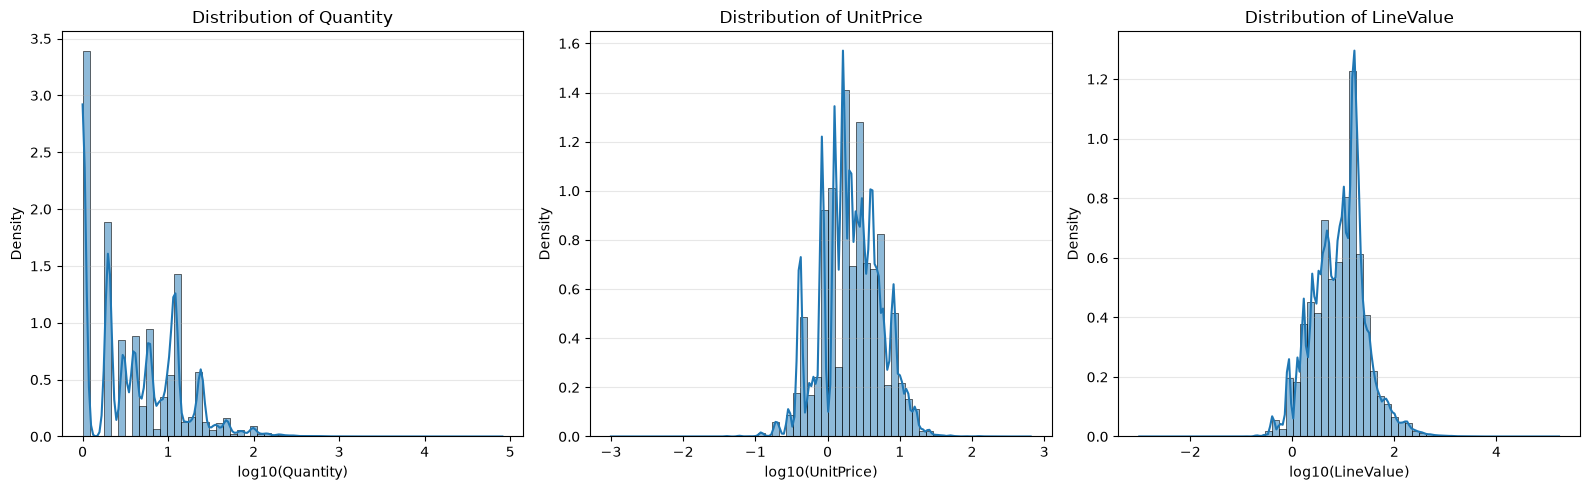

In [60]:
fig = Figure(figsize=(16, 5))
axes = fig.subplots(1, 3)

for ax, column in zip(axes, QUANTITATIVE_VARIABLES):
    transformed_values = np.log10(df_eda[column])

    sns.histplot(
        x=transformed_values,
        bins=60,
        stat="density",
        kde=True,
        ax=ax,
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(f"log10({column})")
    ax.set_ylabel("Density")
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.canvas.draw()
display(fig)

### 6.2.5 Visualizing Dispersion with Box Plots

Histograms help us understand distributional shape. Box plots provide a complementary view of central tendency, dispersion, and potential extreme observations.

A standard box plot displays:

- Median: the line inside the box.
- First and third quartiles: the lower and upper boundaries of the box.
- Interquartile range: the height of the box.
- Whiskers: the range of observations within the conventional 1.5 × IQR criterion.
- Fliers: observations beyond the whiskers.

Because our variables have extreme upper tails, we will use logarithmic vertical axes.

We will hide individual fliers to keep the plots readable. This does not remove observations from the dataset or change the box-and-whisker calculations.

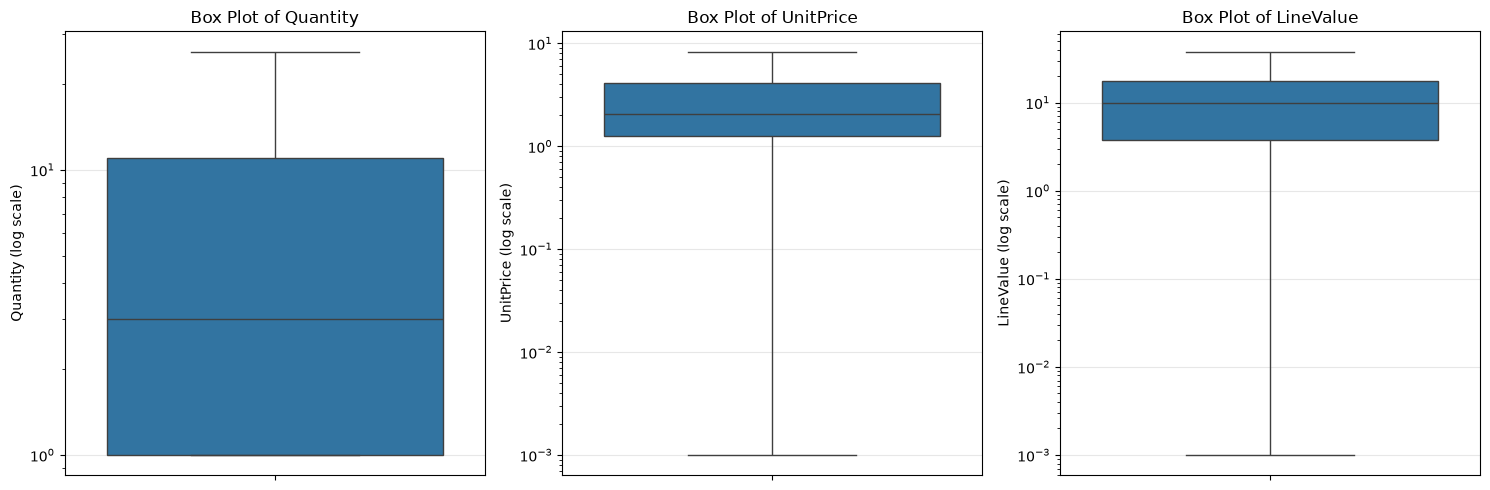

In [61]:
fig = Figure(figsize=(15, 5))
axes = fig.subplots(1, 3)

for ax, column in zip(axes, QUANTITATIVE_VARIABLES):
    sns.boxplot(
        y=df_eda[column],
        showfliers=False,
        ax=ax,
    )

    ax.set_yscale("log")
    ax.set_title(f"Box Plot of {column}")
    ax.set_ylabel(f"{column} (log scale)")
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.canvas.draw()
display(fig)

### 6.2.6 Identifying Potential Outliers with the IQR Rule

We will use the conventional 1.5 × IQR rule to identify potential outliers in the three quantitative variables.

An observation is flagged when:

- It is below the lower fence, or
- It is above the upper fence.

These are statistical flags, not proof of data errors.

This distinction is particularly important for our dataset because all three variables have strongly right-skewed distributions. Legitimate high-volume purchases, expensive products, and high-value line items may be flagged.

We will quantify the flagged observations but will not remove them automatically.

In [62]:
outlier_summary = []

for column in QUANTITATIVE_VARIABLES:
    q1 = df_eda[column].quantile(0.25)
    q3 = df_eda[column].quantile(0.75)

    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    lower_outliers = df_eda[column] < lower_fence
    upper_outliers = df_eda[column] > upper_fence
    outlier_mask = lower_outliers | upper_outliers

    outlier_count = outlier_mask.sum()

    outlier_summary.append({
        "variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "lower_outliers": lower_outliers.sum(),
        "upper_outliers": upper_outliers.sum(),
        "total_outliers": outlier_count,
        "outlier_percentage": (
            outlier_count / len(df_eda) * 100
        ),
    })

outlier_summary = pd.DataFrame(outlier_summary).set_index("variable")

display(outlier_summary)

,Q1,Q3,IQR,lower_fence,upper_fence,lower_outliers,upper_outliers,total_outliers,outlier_percentage
variable,,,,,,,,,
Quantity,1.00,11.00,10.00,-14.000,26.000,0,27115,27115,5.135922
UnitPrice,1.25,4.13,2.88,-3.070,8.450,0,36098,36098,6.837416
LineValue,3.75,17.46,13.71,-16.815,38.025,0,41696,41696,7.897748


### 6.2.7 Investigating Extreme Observations

We will inspect the largest observations in each quantitative variable.

The purpose is not to remove extreme values, but to understand their characteristics and determine whether they represent plausible business activity, unusual transactions, or potential data-quality concerns.

We will retain the original dataset throughout this investigation.

In [63]:
for column in QUANTITATIVE_VARIABLES:
    print(f"\nTop 10 observations by {column}")

    display(
        df_eda.nlargest(10, column)[
            [
                "InvoiceNo",
                "StockCode",
                "Description",
                "Quantity",
                "UnitPrice",
                "LineValue",
                "Country",
                "InvoiceDate",
            ]
        ]
    )


Top 10 observations by Quantity


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate
526474,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom,2011-12-09 09:15:00
60026,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom,2011-01-18 10:01:00
409918,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,United Kingdom,2011-10-27 12:26:00
200194,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,United Kingdom,2011-05-27 10:52:00
94711,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,United Kingdom,2011-02-22 10:43:00
263122,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,United Kingdom,2011-07-19 17:04:00
51244,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom,2011-01-11 12:55:00
155931,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom,2011-04-18 13:20:00
421830,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00,United Kingdom,2011-11-02 11:24:00
4856,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40,United Kingdom,2010-12-02 17:38:00



Top 10 observations by UnitPrice


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate
216318,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,38970.0,United Kingdom,2011-06-10 15:28:00
216319,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,649.5,United Kingdom,2011-06-10 15:33:00
4900,536835,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0,United Kingdom,2010-12-02 18:06:00
31647,539080,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0,United Kingdom,2010-12-16 08:41:00
50220,540647,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0,United Kingdom,2011-01-10 14:57:00
80505,543253,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0,United Kingdom,2011-02-04 15:32:00
115508,546480,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0,United Kingdom,2011-03-14 11:38:00
130298,547814,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0,United Kingdom,2011-03-25 14:19:00
166292,551393,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0,United Kingdom,2011-04-28 12:22:00
199859,554836,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0,United Kingdom,2011-05-26 16:25:00



Top 10 observations by LineValue


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate
526474,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom,2011-12-09 09:15:00
60026,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom,2011-01-18 10:01:00
216318,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom,2011-06-10 15:28:00
338664,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom,2011-09-20 11:05:00
51244,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom,2011-01-11 12:55:00
155931,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom,2011-04-18 13:20:00
409887,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands,2011-10-27 12:11:00
51242,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,4921.50,United Kingdom,2011-01-11 12:55:00
455192,576365,22086,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,4781.60,United Kingdom,2011-11-14 17:55:00
155927,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,4632.00,United Kingdom,2011-04-18 13:20:00


### 6.2.8 Checking Extreme Quantities Against the Complete Dataset

The two largest quantity observations are unusually large:

- Invoice 581483, StockCode 23843: 80,995 units.
- Invoice 541431, StockCode 23166: 74,215 units.

We will search the complete prepared dataset for these invoice numbers and stock codes.

This investigation may help us determine whether these observations have corresponding cancellation records or other unusual transaction patterns.

We will not modify or remove any records.

In [64]:
extreme_cases = [
    ("581483", "23843"),
    ("541431", "23166"),
]

for invoice_no, stock_code in extreme_cases:
    print(f"\nInvoice: {invoice_no} | StockCode: {stock_code}")

    matching_records = df_analysis.loc[
        (
            df_analysis["InvoiceNo"].astype("string")
            == invoice_no
        )
        |
        (
            df_analysis["StockCode"].astype("string")
            == stock_code
        )
    ].copy()

    display(
        matching_records[
            [
                "InvoiceNo",
                "StockCode",
                "Description",
                "Quantity",
                "UnitPrice",
                "LineValue",
                "Country",
                "InvoiceDate",
                "TransactionCategory",
            ]
        ].sort_values(
            ["StockCode", "InvoiceDate", "InvoiceNo"]
        )
    )


Invoice: 581483 | StockCode: 23843


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate,TransactionCategory
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,United Kingdom,2011-12-09 09:15:00,Positive-priced transaction
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6,United Kingdom,2011-12-09 09:27:00,Cancellation / credit-note candidate



Invoice: 541431 | StockCode: 23166


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate,TransactionCategory
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom,2011-01-18 10:01:00,Positive-priced transaction
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.60,United Kingdom,2011-01-18 10:17:00,Cancellation / credit-note candidate
186770,552882,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,99.84,Netherlands,2011-05-12 10:10:00,Positive-priced transaction
187196,552953,23166,MEDIUM CERAMIC TOP STORAGE JAR,4,1.25,5.00,United Kingdom,2011-05-12 12:11:00,Positive-priced transaction
187718,553005,23166,MEDIUM CERAMIC TOP STORAGE JAR,5,1.25,6.25,United Kingdom,2011-05-12 16:29:00,Positive-priced transaction
...,...,...,...,...,...,...,...,...,...
533742,581108,23166,MEDIUM CERAMIC TOP STORAGE JAR,2,1.25,2.50,United Kingdom,2011-12-07 12:16:00,Positive-priced transaction
536248,581219,23166,MEDIUM CERAMIC TOP STORAGE JAR,1,2.46,2.46,United Kingdom,2011-12-08 09:28:00,Positive-priced transaction
539776,581439,23166,MEDIUM CERAMIC TOP STORAGE JAR,2,2.46,4.92,United Kingdom,2011-12-08 16:30:00,Positive-priced transaction
540301,581476,23166,MEDIUM CERAMIC TOP STORAGE JAR,48,1.04,49.92,Norway,2011-12-09 08:48:00,Positive-priced transaction


### 6.2.9 Investigating Cancellation Counterparts for Extreme Quantities

We will identify positive sales candidates with unusually high quantities and search the complete prepared dataset for matching cancellation records.

A matching counterpart will require:

- The same StockCode.
- The same absolute Quantity.
- The same UnitPrice.
- The same absolute LineValue.
- A cancellation invoice prefix (`C`).

This is a matching rule for investigation, not proof of a formal relationship between invoice records.

In [65]:
quantity_outlier_threshold = (
    quantitative_summary.loc["Quantity", "75%"]
    + 1.5 * quantitative_summary.loc["Quantity", "IQR"]
)

extreme_quantity_records = df_eda.loc[
    df_eda["Quantity"] > quantity_outlier_threshold,
    [
        "InvoiceNo",
        "StockCode",
        "Quantity",
        "UnitPrice",
        "LineValue",
    ],
].copy()

cancellation_records = df_analysis.loc[
    df_analysis["InvoicePrefix"] == "C",
    [
        "InvoiceNo",
        "StockCode",
        "Quantity",
        "UnitPrice",
        "LineValue",
    ],
].copy()

cancellation_records["AbsQuantity"] = cancellation_records["Quantity"].abs()
cancellation_records["AbsLineValue"] = cancellation_records["LineValue"].abs()

extreme_quantity_records["AbsQuantity"] = extreme_quantity_records["Quantity"].abs()
extreme_quantity_records["AbsLineValue"] = extreme_quantity_records["LineValue"].abs()

matched_extreme_quantities = extreme_quantity_records.merge(
    cancellation_records,
    on=["StockCode", "AbsQuantity", "UnitPrice", "AbsLineValue"],
    how="inner",
    suffixes=("_original", "_cancellation"),
)

print("Quantity outlier records:", len(extreme_quantity_records))
print("Records with matching cancellation candidates:", len(matched_extreme_quantities))
print(
    "Percentage with matching counterparts:",
    round(
        len(matched_extreme_quantities)
        / len(extreme_quantity_records) * 100,
        3,
    ),
    "%",
)

display(
    matched_extreme_quantities[
        [
            "InvoiceNo_original",
            "InvoiceNo_cancellation",
            "StockCode",
            "Quantity_original",
            "Quantity_cancellation",
            "UnitPrice",
            "LineValue_original",
            "LineValue_cancellation",
        ]
    ].head(20)
)

Quantity outlier records: 27115
Records with matching cancellation candidates: 6833
Percentage with matching counterparts: 25.2 %


,InvoiceNo_original,InvoiceNo_cancellation,StockCode,Quantity_original,Quantity_cancellation,UnitPrice,LineValue_original,LineValue_cancellation
0,536370,C558436,22492,36,-36,0.65,23.4,-23.4
1,536370,C560540,22492,36,-36,0.65,23.4,-23.4
2,536370,C570486,22492,36,-36,0.65,23.4,-23.4
3,536370,C570867,22492,36,-36,0.65,23.4,-23.4
4,536384,C577786,22469,40,-40,1.45,58.0,-58.0
5,536386,C540417,85099B,100,-100,1.65,165.0,-165.0
6,536390,C570850,22910,40,-40,2.55,102.0,-102.0
7,536390,C540417,85099B,100,-100,1.65,165.0,-165.0
8,536394,C578368,22866,96,-96,1.85,177.6,-177.6
9,536402,C549191,22086,40,-40,2.55,102.0,-102.0


### 6.2.10 Understanding the Structure of Cancellation Records

Before attempting to link cancellations to original transactions, we need to understand their characteristics.

We will examine:

1. Number of cancellation records and unique cancellation invoices.
2. Distribution of cancellation quantities and unit prices.
3. Number of cancellation records per invoice.
4. Whether cancellation invoices contain multiple product lines.

This will help us determine whether invoice-level matching is feasible.

In [66]:
cancellations = df_analysis.loc[
    df_analysis["InvoicePrefix"] == "C"
].copy()

cancellation_summary = pd.Series(
    {
        "record_count": len(cancellations),
        "unique_invoices": cancellations["InvoiceNo"].nunique(),
        "unique_stock_codes": cancellations["StockCode"].nunique(),
        "unique_customers": cancellations["CustomerID"].nunique(),
        "unique_countries": cancellations["Country"].nunique(),
        "earliest_cancellation": cancellations["InvoiceDate"].min(),
        "latest_cancellation": cancellations["InvoiceDate"].max(),
        "negative_quantity_records": (cancellations["Quantity"] < 0).sum(),
        "positive_quantity_records": (cancellations["Quantity"] > 0).sum(),
        "zero_quantity_records": (cancellations["Quantity"] == 0).sum(),
    },
    name="value",
)

display(cancellation_summary.to_frame())

,value
record_count,9288
unique_invoices,3836
unique_stock_codes,1947
unique_customers,1589
unique_countries,30
earliest_cancellation,2010-12-01 09:41:00
latest_cancellation,2011-12-09 11:58:00
negative_quantity_records,9288
positive_quantity_records,0
zero_quantity_records,0


### 6.2.11 Examining Cancellation Invoice Composition

A cancellation invoice may contain one or multiple product lines.

If cancellation invoices contain multiple lines, matching should consider the complete invoice composition rather than relying on an isolated product and quantity.

We will calculate the number of records per cancellation invoice and summarize its distribution.

In [67]:
cancellation_invoice_sizes = (
    cancellations.groupby("InvoiceNo")
    .size()
    .rename("line_count")
)

display(
    cancellation_invoice_sizes.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame()
)

print("\nCancellation invoices by number of lines:")

display(
    cancellation_invoice_sizes.value_counts()
    .sort_index()
    .rename_axis("line_count")
    .to_frame("invoice_count")
)

,line_count
count,3836.000000
mean,2.421272
std,3.759914
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
90%,4.000000
95%,7.000000
99%,18.000000



Cancellation invoices by number of lines:


,invoice_count
line_count,
1,2131
2,773
3,399
4,150
5,104
6,57
7,52
8,27
9,24


### 6.2.12 Testing Customer-Aware Cancellation Matching

We will attempt to associate cancellation records with earlier positive sales candidates using:

- CustomerID
- StockCode
- Absolute Quantity
- UnitPrice
- Country
- Transaction chronology

Only records with an identifiable CustomerID can participate in this test.

For each cancellation line, we will count how many earlier positive transaction lines satisfy these conditions.

Interpretation:

- Zero candidates: no matching earlier transaction was found.
- One candidate: one possible original transaction was found.
- Multiple candidates: the association is ambiguous.

Even a unique candidate is not definitive proof of a cancellation relationship.

In [68]:
positive_records = df_eda.loc[
    df_eda["CustomerID"].notna()
].copy()

cancellation_records_with_customer = cancellations.loc[
    cancellations["CustomerID"].notna()
].copy()

positive_match_data = positive_records[
    [
        "CustomerID",
        "StockCode",
        "Quantity",
        "UnitPrice",
        "Country",
        "InvoiceDate",
        "InvoiceNo",
    ]
].copy()

cancellation_match_data = cancellation_records_with_customer[
    [
        "CustomerID",
        "StockCode",
        "Quantity",
        "UnitPrice",
        "Country",
        "InvoiceDate",
        "InvoiceNo",
    ]
].copy()

positive_match_data = positive_match_data.rename(
    columns={
        "InvoiceDate": "original_date",
        "InvoiceNo": "original_invoice",
    }
)

cancellation_match_data = cancellation_match_data.rename(
    columns={
        "InvoiceDate": "cancellation_date",
        "InvoiceNo": "cancellation_invoice",
    }
)

cancellation_match_data["cancellation_row_id"] = (
    cancellation_match_data.index
)

positive_match_data["AbsQuantity"] = (
    positive_match_data["Quantity"].abs()
)

cancellation_match_data["AbsQuantity"] = (
    cancellation_match_data["Quantity"].abs()
)

possible_matches = cancellation_match_data.merge(
    positive_match_data,
    on=[
        "CustomerID",
        "StockCode",
        "AbsQuantity",
        "UnitPrice",
        "Country",
    ],
    how="left",
    suffixes=("_cancellation", "_original"),
)

possible_matches = possible_matches.loc[
    possible_matches["original_date"]
    < possible_matches["cancellation_date"]
].copy()

candidate_counts = (
    possible_matches.groupby("cancellation_row_id")
    .size()
    .rename("candidate_count")
)

cancellation_match_results = (
    cancellation_match_data[
        ["cancellation_row_id"]
    ]
    .drop_duplicates()
    .merge(
        candidate_counts,
        on="cancellation_row_id",
        how="left",
    )
)

cancellation_match_results["candidate_count"] = (
    cancellation_match_results["candidate_count"]
    .fillna(0)
    .astype(int)
)

match_distribution = (
    cancellation_match_results["candidate_count"]
    .value_counts()
    .sort_index()
    .rename_axis("candidate_count")
    .to_frame("cancellation_line_count")
)

display(match_distribution)

print("\nMatching summary:")
print(
    "Cancellation lines with identifiable customers:",
    len(cancellation_match_results),
)
print(
    "Cancellation lines with at least one earlier candidate:",
    (cancellation_match_results["candidate_count"] > 0).sum(),
)
print(
    "Cancellation lines with exactly one candidate:",
    (cancellation_match_results["candidate_count"] == 1).sum(),
)
print(
    "Cancellation lines with multiple candidates:",
    (cancellation_match_results["candidate_count"] > 1).sum(),
)

,cancellation_line_count
candidate_count,
0,6132
1,2168
2,386
3,101
4,55
5,16
6,9
7,11
8,7



Matching summary:
Cancellation lines with identifiable customers: 8905
Cancellation lines with at least one earlier candidate: 2773
Cancellation lines with exactly one candidate: 2168
Cancellation lines with multiple candidates: 605


### 6.2.13 Reviewing Candidate Matches and Time Gaps

We will investigate two groups:

1. Cancellation lines with exactly one earlier candidate.
2. Cancellation lines with multiple earlier candidates.

For unique candidates, we will calculate the elapsed time between the two records.

For ambiguous cases, we will inspect several examples to understand why multiple possible originals exist.

A shorter time gap may strengthen a possible association, but it is not sufficient evidence to establish a definitive match.

In [69]:
possible_matches["time_gap_hours"] = (
    possible_matches["cancellation_date"]
    - possible_matches["original_date"]
).dt.total_seconds() / 3600

unique_ids = cancellation_match_results.loc[
    cancellation_match_results["candidate_count"] == 1,
    "cancellation_row_id",
]

unique_matches = possible_matches.loc[
    possible_matches["cancellation_row_id"].isin(unique_ids)
].copy()

print("Unique candidate time-gap distribution:")

display(
    unique_matches["time_gap_hours"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame("hours")
)

print("\nSample of unique candidate matches:")

display(
    unique_matches[
        [
            "original_invoice",
            "cancellation_invoice",
            "CustomerID",
            "StockCode",
            "Quantity_original",
            "UnitPrice",
            "original_date",
            "cancellation_date",
            "time_gap_hours",
        ]
    ].head(20)
)

ambiguous_ids = cancellation_match_results.loc[
    cancellation_match_results["candidate_count"] > 1,
    "cancellation_row_id",
].head(5)

print("\nExamples of ambiguous cancellation lines:")

display(
    possible_matches.loc[
        possible_matches["cancellation_row_id"].isin(ambiguous_ids),
        [
            "original_invoice",
            "cancellation_invoice",
            "CustomerID",
            "StockCode",
            "Quantity_original",
            "UnitPrice",
            "original_date",
            "cancellation_date",
            "time_gap_hours",
        ],
    ].sort_values(
        ["cancellation_invoice", "original_date"]
    )
)

Unique candidate time-gap distribution:


,hours
count,2168.000000
mean,637.244942
std,1057.295913
min,0.016667
25%,48.183333
50%,237.808333
75%,719.150000
90%,1678.310000
95%,2976.294167
99%,5000.626167



Sample of unique candidate matches:


,original_invoice,cancellation_invoice,CustomerID,StockCode,Quantity_original,UnitPrice,original_date,cancellation_date,time_gap_hours
90,536557,C536979,17841,84685,1.0,3.75,2010-12-01 14:41:00,2010-12-03 14:23:00,47.700000
109,537140,C537143,12748,20685,1.0,7.95,2010-12-05 12:53:00,2010-12-05 12:58:00,0.083333
111,537144,C537157,15880,35953,24.0,1.25,2010-12-05 13:00:00,2010-12-05 13:09:00,0.150000
113,536591,C537203,14606,37449,1.0,9.95,2010-12-01 16:57:00,2010-12-05 14:44:00,93.783333
119,537298,C537314,13497,21349,4.0,6.75,2010-12-06 11:37:00,2010-12-06 11:42:00,0.083333
125,537377,C537379,15882,22865,10.0,2.10,2010-12-06 13:01:00,2010-12-06 13:12:00,0.183333
131,537217,C537402,15502,22926,4.0,5.95,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
133,537217,C537402,15502,22927,4.0,5.95,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
135,537217,C537402,15502,22849,4.0,14.95,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000
137,537217,C537402,15502,22847,4.0,14.95,2010-12-05 15:40:00,2010-12-06 14:43:00,23.050000



Examples of ambiguous cancellation lines:


,original_invoice,cancellation_invoice,CustomerID,StockCode,Quantity_original,UnitPrice,original_date,cancellation_date,time_gap_hours
129,537196,C537398,15426,22430,1.0,4.95,2010-12-05 13:55:00,2010-12-06 14:22:00,24.450000
130,537196,C537398,15426,22430,1.0,4.95,2010-12-05 13:55:00,2010-12-06 14:22:00,24.450000
219,537773,C537820,16016,22627,1.0,8.50,2010-12-08 12:36:00,2010-12-08 14:10:00,1.566667
220,537773,C537820,16016,22627,1.0,8.50,2010-12-08 12:36:00,2010-12-08 14:10:00,1.566667
336,538313,C538341,15514,84380,1.0,1.25,2010-12-10 13:50:00,2010-12-10 14:03:00,0.216667
342,538313,C538341,15514,22976,12.0,1.25,2010-12-10 13:50:00,2010-12-10 14:03:00,0.216667
343,538313,C538341,15514,22976,12.0,1.25,2010-12-10 13:50:00,2010-12-10 14:03:00,0.216667
344,538313,C538341,15514,22976,12.0,1.25,2010-12-10 13:50:00,2010-12-10 14:03:00,0.216667
345,538313,C538341,15514,22976,12.0,1.25,2010-12-10 13:50:00,2010-12-10 14:03:00,0.216667
346,538313,C538341,15514,22976,12.0,1.25,2010-12-10 13:50:00,2010-12-10 14:03:00,0.216667


In [70]:
# Count distinct original invoices per cancellation line.
distinct_invoice_counts = (
    possible_matches.groupby("cancellation_row_id")[
        "original_invoice"
    ]
    .nunique()
    .rename("distinct_original_invoice_count")
)

corrected_match_results = (
    cancellation_match_data[["cancellation_row_id"]]
    .drop_duplicates()
    .merge(
        distinct_invoice_counts,
        on="cancellation_row_id",
        how="left",
    )
)

corrected_match_results[
    "distinct_original_invoice_count"
] = (
    corrected_match_results[
        "distinct_original_invoice_count"
    ]
    .fillna(0)
    .astype(int)
)

print("Matching distribution by distinct original invoice:")

display(
    corrected_match_results[
        "distinct_original_invoice_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("candidate_count")
    .to_frame("cancellation_line_count")
)

print("\nCorrected matching summary:")

print(
    "No candidate:",
    (
        corrected_match_results[
            "distinct_original_invoice_count"
        ] == 0
    ).sum(),
)

print(
    "Exactly one distinct original invoice:",
    (
        corrected_match_results[
            "distinct_original_invoice_count"
        ] == 1
    ).sum(),
)

print(
    "Multiple distinct original invoices:",
    (
        corrected_match_results[
            "distinct_original_invoice_count"
        ] > 1
    ).sum(),
)

Matching distribution by distinct original invoice:


,cancellation_line_count
candidate_count,
0,6132
1,2214
2,360
3,84
4,53
5,15
6,10
7,10
8,10



Corrected matching summary:
No candidate: 6132
Exactly one distinct original invoice: 2214
Multiple distinct original invoices: 559


### 6.2.15 Comparing Original and Cancellation Invoice Composition

We will inspect selected original and cancellation invoices together.

The objective is to determine whether complete invoice composition provides stronger evidence of cancellation relationships than individual line matching.

We will compare:
- Customer identity
- Product codes
- Quantities
- Unit prices
- Line values
- Invoice totals
- Transaction timestamps

We will treat identical invoice compositions as stronger evidence, but not as definitive proof of a formal linkage.

In [71]:
invoice_pairs_to_inspect = [
    ("538313", "C538341"),
    ("537140", "C537143"),
    ("581483", "C581484"),
]

for original_invoice, cancellation_invoice in invoice_pairs_to_inspect:
    print(f"\nOriginal invoice: {original_invoice}")
    print(f"Cancellation invoice: {cancellation_invoice}")

    invoice_records = df_analysis.loc[
        df_analysis["InvoiceNo"].astype("string").isin(
            [original_invoice, cancellation_invoice]
        )
    ].copy()

    display(
        invoice_records[
            [
                "InvoiceNo",
                "CustomerID",
                "StockCode",
                "Description",
                "Quantity",
                "UnitPrice",
                "LineValue",
                "Country",
                "InvoiceDate",
            ]
        ].sort_values(
            ["InvoiceNo", "StockCode", "Quantity"]
        )
    )

    print("Invoice-level summary:")

    display(
        invoice_records.groupby("InvoiceNo").agg(
            line_count=("StockCode", "size"),
            customer_count=("CustomerID", "nunique"),
            stock_code_count=("StockCode", "nunique"),
            total_quantity=("Quantity", "sum"),
            total_line_value=("LineValue", "sum"),
            invoice_date=("InvoiceDate", "min"),
        )
    )


Original invoice: 538313
Cancellation invoice: C538341


,InvoiceNo,CustomerID,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate
24101,538313,15514,16258A,SWIRLY CIRCULAR RUBBERS IN BAG,1,0.42,0.42,United Kingdom,2010-12-10 13:50:00
24112,538313,15514,21056,DOCTOR'S BAG SOFT TOY,1,8.95,8.95,United Kingdom,2010-12-10 13:50:00
24099,538313,15514,21644,ASSORTED TUTTI FRUTTI HEART BOX,1,1.25,1.25,United Kingdom,2010-12-10 13:50:00
24102,538313,15514,21647,ASSORTED TUTTI FRUTTI LARGE PURSE,1,2.10,2.10,United Kingdom,2010-12-10 13:50:00
24100,538313,15514,21731,RED TOADSTOOL LED NIGHT LIGHT,1,1.65,1.65,United Kingdom,2010-12-10 13:50:00
...,...,...,...,...,...,...,...,...,...
24162,C538341,15514,22976,CIRCUS PARADE CHILDRENS EGG CUP,-12,1.25,-15.00,United Kingdom,2010-12-10 14:03:00
24163,C538341,15514,22976,CIRCUS PARADE CHILDRENS EGG CUP,-12,1.25,-15.00,United Kingdom,2010-12-10 14:03:00
24159,C538341,15514,22988,SOLDIERS EGG CUP,-36,1.25,-45.00,United Kingdom,2010-12-10 14:03:00
24160,C538341,15514,22988,SOLDIERS EGG CUP,-12,1.25,-15.00,United Kingdom,2010-12-10 14:03:00


Invoice-level summary:


,line_count,customer_count,stock_code_count,total_quantity,total_line_value,invoice_date
InvoiceNo,,,,,,
538313,39,1,23,322,1136.32,2010-12-10 13:50:00
C538341,39,1,23,-322,-1136.32,2010-12-10 14:03:00



Original invoice: 537140
Cancellation invoice: C537143


,InvoiceNo,CustomerID,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate
8594,537140,12748,16011,ANIMAL STICKERS,5,0.21,1.05,United Kingdom,2010-12-05 12:53:00
8593,537140,12748,20685,DOORMAT RED RETROSPOT,1,7.95,7.95,United Kingdom,2010-12-05 12:53:00
8604,537140,12748,20973,12 PENCIL SMALL TUBE WOODLAND,4,0.65,2.60,United Kingdom,2010-12-05 12:53:00
8612,537140,12748,21650,ASSORTED TUTTI FRUTTI BRACELET,1,0.65,0.65,United Kingdom,2010-12-05 12:53:00
8606,537140,12748,21650,ASSORTED TUTTI FRUTTI BRACELET,2,0.65,1.30,United Kingdom,2010-12-05 12:53:00
8608,537140,12748,21650,ASSORTED TUTTI FRUTTI BRACELET,3,0.65,1.95,United Kingdom,2010-12-05 12:53:00
8600,537140,12748,21785,RAIN PONCHO,1,0.85,0.85,United Kingdom,2010-12-05 12:53:00
8601,537140,12748,21786,POLKADOT RAIN HAT,1,0.42,0.42,United Kingdom,2010-12-05 12:53:00
8602,537140,12748,21787,RAIN PONCHO RETROSPOT,1,0.85,0.85,United Kingdom,2010-12-05 12:53:00
8610,537140,12748,21790,VINTAGE SNAP CARDS,1,0.85,0.85,United Kingdom,2010-12-05 12:53:00


... (2 outputs left out)


Original invoice: 581483
Cancellation invoice: C581484


,InvoiceNo,CustomerID,StockCode,Description,Quantity,UnitPrice,LineValue,Country,InvoiceDate
540421,581483,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,United Kingdom,2011-12-09 09:15:00
540422,C581484,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6,United Kingdom,2011-12-09 09:27:00


Invoice-level summary:


,line_count,customer_count,stock_code_count,total_quantity,total_line_value,invoice_date
InvoiceNo,,,,,,
581483,1,1,1,80995,168469.6,2011-12-09 09:15:00
C581484,1,1,1,-80995,-168469.6,2011-12-09 09:27:00


### 6.2.16 Identifying Full Invoice Reversals

### Building Aggregated Invoice Compositions

Repeated lines for the same stock code and unit price are combined within each invoice.

For each invoice, we construct a composition signature containing:
- Stock code
- Unit price
- Aggregated quantity

For cancellation invoices, quantities are converted to absolute values so their composition can be compared directly with positive invoices.

In [72]:
def build_invoice_compositions(data, cancellation=False):
    work = data.loc[
        data["CustomerID"].notna(),
        [
            "InvoiceNo",
            "CustomerID",
            "Country",
            "InvoiceDate",
            "StockCode",
            "Quantity",
            "UnitPrice",
        ],
    ].copy()

    work["InvoiceNo"] = work["InvoiceNo"].astype("string")
    work["UnitPriceRounded"] = work["UnitPrice"].round(2)

    line_compositions = (
        work.groupby(
            [
                "InvoiceNo",
                "CustomerID",
                "Country",
                "StockCode",
                "UnitPriceRounded",
            ],
            as_index=False,
            observed=True,
        )
        .agg(aggregated_quantity=("Quantity", "sum"))
    )

    invoice_dates = (
        work.groupby("InvoiceNo")["InvoiceDate"]
        .min()
    )

    invoice_records = []

    for (invoice, customer, country), group in line_compositions.groupby(
        ["InvoiceNo", "CustomerID", "Country"],
        sort=False,
        observed=True,
    ):
        signature = tuple(
            sorted(
                (
                    str(row.StockCode),
                    float(row.UnitPriceRounded),
                    abs(int(row.aggregated_quantity))
                    if cancellation
                    else int(row.aggregated_quantity),
                )
                for row in group.itertuples()
            )
        )

        invoice_records.append(
            {
                "InvoiceNo": invoice,
                "CustomerID": customer,
                "Country": country,
                "InvoiceDate": invoice_dates.loc[invoice],
                "line_count_after_aggregation": len(group),
                "composition_signature": signature,
            }
        )

    return pd.DataFrame(invoice_records)

original_invoice_compositions = build_invoice_compositions(df_eda)

cancellation_invoice_compositions = build_invoice_compositions(
    df_analysis.loc[df_analysis["InvoicePrefix"].eq("C")],
    cancellation=True,
)

print("Original invoices:", len(original_invoice_compositions))
print("Cancellation invoices:", len(cancellation_invoice_compositions))

display(original_invoice_compositions.head())
display(cancellation_invoice_compositions.head())

Original invoices: 18416
Cancellation invoices: 3654


,InvoiceNo,CustomerID,Country,InvoiceDate,line_count_after_aggregation,composition_signature
0,536365,17850,United Kingdom,2010-12-01 08:26:00,7,"((21730, 4.25, 6), (22752, 7.65, 2), (71053, 3..."
1,536366,17850,United Kingdom,2010-12-01 08:28:00,2,"((22632, 1.85, 6), (22633, 1.85, 6))"
2,536367,13047,United Kingdom,2010-12-01 08:34:00,12,"((21754, 5.95, 3), (21755, 5.95, 3), (21777, 7..."
3,536368,13047,United Kingdom,2010-12-01 08:34:00,4,"((22912, 4.95, 3), (22913, 4.95, 3), (22914, 4..."
4,536369,13047,United Kingdom,2010-12-01 08:35:00,1,"((21756, 5.95, 3),)"


,InvoiceNo,CustomerID,Country,InvoiceDate,line_count_after_aggregation,composition_signature
0,C536379,14527,United Kingdom,2010-12-01 09:41:00,1,"((D, 27.5, 1),)"
1,C536383,15311,United Kingdom,2010-12-01 09:49:00,1,"((35004C, 4.65, 1),)"
2,C536391,17548,United Kingdom,2010-12-01 10:24:00,7,"((21484, 3.45, 12), (21980, 0.29, 24), (21983,..."
3,C536506,17897,United Kingdom,2010-12-01 12:38:00,1,"((22960, 4.25, 6),)"
4,C536543,17841,United Kingdom,2010-12-01 14:30:00,2,"((22355, 0.85, 2), (22632, 2.1, 1))"


### Matching Full Invoice Reversals

We now compare each cancellation invoice against earlier positive-sales invoices.

A candidate must have:
1. The same CustomerID.
2. The same Country.
3. An identical aggregated product composition.
4. An earlier transaction date.

We count distinct original invoice numbers rather than matching rows.

An exact composition match is strong evidence of a full reversal, but it is still an inferred relationship rather than a documented invoice reference.

In [73]:
from collections import defaultdict

original_invoice_lookup = defaultdict(list)

for row in original_invoice_compositions.itertuples(index=False):
    lookup_key = (
        row.CustomerID,
        row.Country,
        row.composition_signature,
    )

    original_invoice_lookup[lookup_key].append(
        (row.InvoiceNo, row.InvoiceDate)
    )

full_reversal_candidates = []

for cancellation in cancellation_invoice_compositions.itertuples(index=False):
    lookup_key = (
        cancellation.CustomerID,
        cancellation.Country,
        cancellation.composition_signature,
    )

    earlier_candidates = [
        original_invoice
        for original_invoice, original_date
        in original_invoice_lookup.get(lookup_key, [])
        if original_date < cancellation.InvoiceDate
    ]

    full_reversal_candidates.append(
        {
            "cancellation_invoice": cancellation.InvoiceNo,
            "cancellation_date": cancellation.InvoiceDate,
            "distinct_original_invoice_count": len(earlier_candidates),
            "candidate_original_invoices": earlier_candidates,
        }
    )

full_reversal_results = pd.DataFrame(full_reversal_candidates)

display(
    full_reversal_results[
        "distinct_original_invoice_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("candidate_count")
    .to_frame("cancellation_invoice_count")
)

print(
    "No candidate:",
    (full_reversal_results["distinct_original_invoice_count"] == 0).sum(),
)

print(
    "Exactly one candidate:",
    (full_reversal_results["distinct_original_invoice_count"] == 1).sum(),
)

print(
    "Multiple candidates:",
    (full_reversal_results["distinct_original_invoice_count"] > 1).sum(),
)

,cancellation_invoice_count
candidate_count,
0,3542
1,103
2,7
3,2


No candidate: 3542
Exactly one candidate: 103
Multiple candidates: 9


### Cancellation Matching Investigation — Conclusion

An exploratory invoice-level matching analysis was conducted to identify
potential full invoice reversals.

Invoices were compared using customer identity, country, transaction
chronology, and aggregated product composition.

Among 3,654 cancellation invoices with identifiable customers:
- 103 had exactly one earlier full-composition candidate.
- 7 had two candidates.
- 2 had three candidates.
- 3,542 had no exact earlier full-composition candidate.

These findings suggest that cancellation activity includes different
patterns, potentially including full reversals and partial cancellations.

However, the dataset does not provide a definitive reference linking
cancellation invoices to their original invoices. Consequently, exact
transaction-level relationships cannot be established reliably.

The primary positive-sales-candidate population remains unchanged.
Cancellation records will be treated as a separate analytical population
rather than automatically deducted from positive transaction values.

All matching results are exploratory and should not be interpreted as
verified accounting or revenue adjustments.

## 6.3 Univariate Categorical Analysis

This section examines the distribution of categorical variables and
the frequency of identified products.

We will focus on:
- Geographic distribution by Country.
- Product distribution by StockCode.

The objective is to identify concentration, diversity, and dominant
categories within the positive-sales-candidate population.

### Country Distribution

We will examine transaction records, invoices, identifiable customers,
quantities, and line values across countries.

Record percentages describe the distribution of invoice-line records,
not the percentage of customers or total sales.

In [74]:
country_summary = (
    df_eda.groupby("Country", observed=True)
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        unique_customers=("CustomerID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_line_value=("LineValue", "sum"),
    )
    .sort_values("record_count", ascending=False)
)

country_summary["record_percentage"] = (
    country_summary["record_count"] / len(df_eda) * 100
)

display(country_summary.round(2))

print("Number of countries:", len(country_summary))
print(
    "Top 5 countries' share of records:",
    round(country_summary.head(5)["record_percentage"].sum(), 2),
    "%",
)

,record_count,unique_invoices,unique_customers,total_quantity,total_line_value,record_percentage
Country,,,,,,
United Kingdom,484083,17914,3917,4654436,8749953.07,91.69
Germany,8658,443,94,118139,205569.89,1.64
France,8102,383,87,111272,184768.74,1.53
EIRE,7885,284,3,147168,276404.30,1.49
Spain,2422,88,30,27731,55725.11,0.46
Netherlands,2322,93,9,200258,283889.34,0.44
Switzerland,1935,50,21,30527,53087.90,0.37
Belgium,1935,98,25,22962,36927.34,0.37
Portugal,1464,50,19,16153,27015.16,0.28


Number of countries: 38
Top 5 countries' share of records: 96.82 %


### Product Distribution

StockCode is used as the product identifier because product descriptions
are not guaranteed to be unique or consistent.

We will rank products by:
- Number of invoice-line records.
- Total quantity.
- Total line value.

These measures represent different aspects of product activity and
should not be treated as interchangeable.

In [75]:
product_summary = (
    df_eda.groupby("StockCode", observed=True)
    .agg(
        Description=(
            "Description",
            lambda values: (
                values.mode().iloc[0]
                if not values.mode().empty
                else pd.NA
            ),
        ),
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        unique_customers=("CustomerID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_line_value=("LineValue", "sum"),
    )
)

product_summary = product_summary.sort_values(
    "record_count",
    ascending=False,
)

print("Unique products:", len(product_summary))

print("\nTop 15 products by record count:")
display(product_summary.head(15).round(2))

print("\nTop 15 products by total quantity:")
display(
    product_summary.sort_values(
        "total_quantity", ascending=False
    ).head(15).round(2)
)

print("\nTop 15 products by total line value:")
display(
    product_summary.sort_values(
        "total_line_value", ascending=False
    ).head(15).round(2)
)

Unique products: 3917

Top 15 products by record count:


,Description,record_count,unique_invoices,unique_customers,total_quantity,total_line_value
StockCode,,,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265,2198,856,37660,104518.80
85099B,JUMBO BAG RED RETROSPOT,2112,2089,635,48474,94340.05
22423,REGENCY CAKESTAND 3 TIER,2017,1988,881,13879,174484.74
47566,PARTY BUNTING,1706,1685,708,18295,99504.33
20725,LUNCH BAG RED RETROSPOT,1595,1565,532,19553,36042.01
84879,ASSORTED COLOUR BIRD ORNAMENT,1489,1455,678,36461,59094.93
22197,POPCORN HOLDER,1426,1392,407,56921,51354.02
22720,SET OF 3 CAKE TINS PANTRY DESIGN,1399,1385,640,7493,38158.39
21212,PACK OF 72 RETROSPOT CAKE CASES,1370,1320,635,36419,21259.10



Top 15 products by total quantity:


,Description,record_count,unique_invoices,unique_customers,total_quantity,total_line_value
StockCode,,,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",1,1,1,80995,168469.60
23166,MEDIUM CERAMIC TOP STORAGE JAR,250,247,138,78033,81700.92
22197,POPCORN HOLDER,1426,1392,407,56921,51354.02
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,537,535,307,55047,13841.85
85099B,JUMBO BAG RED RETROSPOT,2112,2089,635,48474,94340.05
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265,2198,856,37660,104518.80
84879,ASSORTED COLOUR BIRD ORNAMENT,1489,1455,678,36461,59094.93
21212,PACK OF 72 RETROSPOT CAKE CASES,1370,1320,635,36419,21259.10
23084,RABBIT NIGHT LIGHT,1036,994,450,30788,66964.99



Top 15 products by total line value:


,Description,record_count,unique_invoices,unique_customers,total_quantity,total_line_value
StockCode,,,,,,
22423,REGENCY CAKESTAND 3 TIER,2017,1988,881,13879,174484.74
23843,"PAPER CRAFT , LITTLE BIRDIE",1,1,1,80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265,2198,856,37660,104518.80
47566,PARTY BUNTING,1706,1685,708,18295,99504.33
85099B,JUMBO BAG RED RETROSPOT,2112,2089,635,48474,94340.05
23166,MEDIUM CERAMIC TOP STORAGE JAR,250,247,138,78033,81700.92
23084,RABBIT NIGHT LIGHT,1036,994,450,30788,66964.99
22086,PAPER CHAIN KIT 50'S CHRISTMAS,1200,1160,613,19355,64952.29
84879,ASSORTED COLOUR BIRD ORNAMENT,1489,1455,678,36461,59094.93


## 6.4 Temporal Exploratory Data Analysis

This section examines how positive-sales-candidate activity varies
over time.

We will analyze:
- Monthly activity.
- Day-of-week activity.
- Hourly activity.

We will compare transaction records, invoices, quantities, and
line values to understand different dimensions of temporal activity.

The dataset spans December 2010 to December 2011. December 2011
contains only the first nine days, so it must be treated as a
partial month.

### Monthly Activity

We aggregate the dataset by calendar month.

The analysis includes invoice-line records, distinct invoices,
identifiable customers, total quantity, and total line value.

Monthly comparisons describe observed activity in this dataset.
They do not independently establish business growth or seasonality.

In [76]:
monthly_summary = (
    df_eda.assign(
        YearMonth=df_eda["InvoiceDate"].dt.to_period("M")
    )
    .groupby("YearMonth", observed=True)
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        unique_customers=("CustomerID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_line_value=("LineValue", "sum"),
    )
)

display(monthly_summary.round(2))

,record_count,unique_invoices,unique_customers,total_quantity,total_line_value
YearMonth,,,,,
2010-12,41329,1552,885,358763,778625.91
2011-01,34156,1082,739,387432,672207.41
2011-02,26972,1093,757,283256,509167.87
2011-03,35623,1440,973,377125,692015.94
2011-04,28971,1237,853,308528,516754.79
2011-05,35993,1669,1055,395405,741726.74
2011-06,35790,1525,990,388843,739426.88
2011-07,38456,1452,946,401369,689947.74
2011-08,34339,1340,933,421459,726005.16


### Day-of-Week Activity

We compare activity across weekdays.

The analysis can reveal whether transaction activity is
distributed evenly across the week or concentrated on particular days.

Only weekdays present in the dataset will appear in the summary.

In [77]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday",
]

weekday_summary = (
    df_eda.groupby("DayOfWeek", observed=True)
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        unique_customers=("CustomerID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_line_value=("LineValue", "sum"),
    )
    .reindex(weekday_order)
    .dropna(how="all")
)

display(weekday_summary.round(2))

,record_count,unique_invoices,unique_customers,total_quantity,total_line_value
DayOfWeek,,,,,
Monday,92734,3082.0,1590.0,870970.0,1687757.53
Tuesday,99010,3513.0,1693.0,1112182.0,2089254.97
Wednesday,91946,3670.0,1769.0,1025069.0,1787752.36
Thursday,100601,4211.0,2001.0,1207657.0,2137615.27
Friday,79872,3110.0,1552.0,890867.0,1771172.01
Sunday,63785,2203.0,1225.0,470548.0,805848.33


### Hourly Activity

We examine how invoice-line activity is distributed across
the hours of the day.

This helps identify periods of higher and lower recorded activity.

The analysis uses the transaction timestamps available in the
dataset; it does not establish store opening hours or staffing levels.

In [78]:
hourly_summary = (
    df_eda.groupby("InvoiceHour", observed=True)
    .agg(
        record_count=("InvoiceNo", "size"),
        unique_invoices=("InvoiceNo", "nunique"),
        unique_customers=("CustomerID", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_line_value=("LineValue", "sum"),
    )
    .reindex(range(24), fill_value=0)
)

display(hourly_summary.round(2))

,record_count,unique_invoices,unique_customers,total_quantity,total_line_value
InvoiceHour,,,,,
0,0,0,0,0,0.00
1,0,0,0,0,0.00
2,0,0,0,0,0.00
3,0,0,0,0,0.00
4,0,0,0,0,0.00
5,0,0,0,0,0.00
6,1,1,1,1,4.25
7,376,29,28,15361,30519.21
8,8746,565,426,158932,279865.52


### Temporal Analysis — Key Findings

Transaction activity varies considerably across months, weekdays, and hours.

November 2011 recorded the highest monthly activity. Activity increased
substantially during September to November, although December 2011 is
incomplete and cannot be compared directly with complete months.

Thursday recorded the highest weekday activity across several measures.
Saturday had no observations, while Sunday activity was present.

Most recorded activity occurred between 9:00 and 16:00, with the
highest record count at 12:00.

These patterns describe the observed transactions and should not
automatically be interpreted as causal business trends or operating hours.

## 6.5 Relationship Analysis

This section examines relationships among quantitative variables.

We focus on Quantity, UnitPrice, and LineValue.

Because the variables are highly right-skewed and contain extreme
observations, correlation coefficients must be interpreted cautiously.

LineValue is calculated as Quantity multiplied by UnitPrice.
Therefore, its relationships with those variables are partly
mathematical rather than independent business relationships.

In [79]:
relationship_variables = [
    "Quantity",
    "UnitPrice",
    "LineValue",
]

pearson_correlation = df_eda[relationship_variables].corr(
    method="pearson"
)

spearman_correlation = df_eda[relationship_variables].corr(
    method="spearman"
)

print("Pearson correlation:")
display(pearson_correlation.round(3))

print("Spearman correlation:")
display(spearman_correlation.round(3))

Pearson correlation:


,Quantity,UnitPrice,LineValue
Quantity,1.000,-0.022,0.916
UnitPrice,-0.022,1.000,0.061
LineValue,0.916,0.061,1.000


Spearman correlation:


,Quantity,UnitPrice,LineValue
Quantity,1.000,-0.402,0.684
UnitPrice,-0.402,1.000,0.332
LineValue,0.684,0.332,1.000


### Visual Examination of Quantitative Relationships

We use log-transformed axes to make the distributions and relationships
more interpretable in the presence of extreme values.

A random sample is used for visualization efficiency. The correlation
calculations above still use the complete analytical population.

Log transformation is used only for visualization; the original
analytical variables remain unchanged.

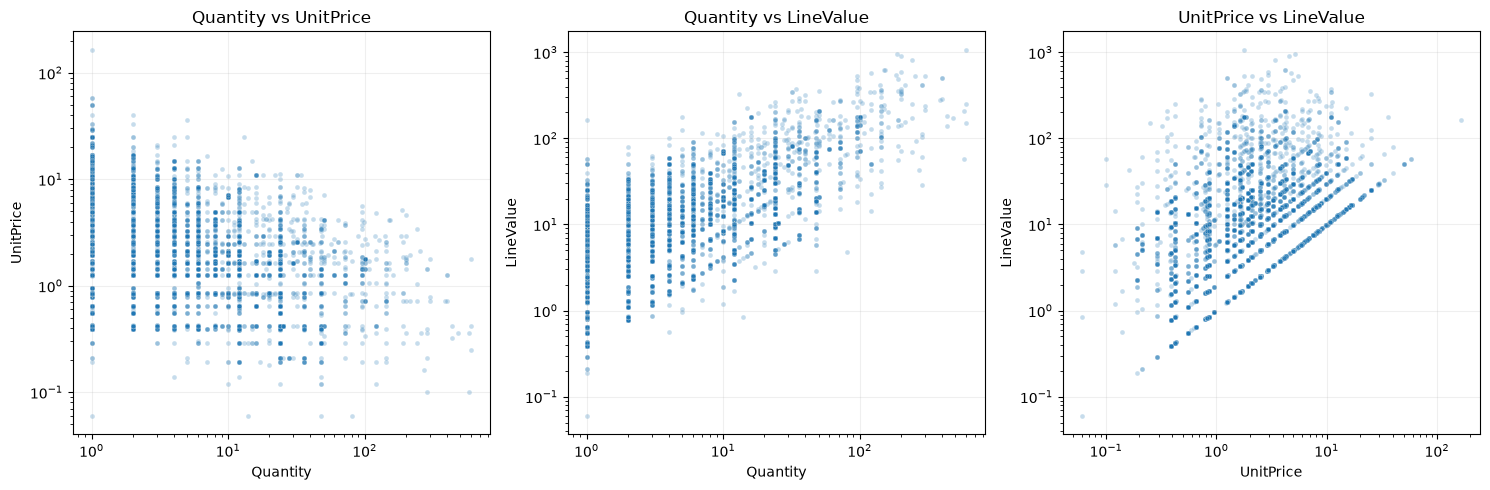

In [80]:
plot_sample = df_eda[relationship_variables].sample(
    n=min(10000, len(df_eda)),
    random_state=42,
)

fig = Figure(figsize=(15, 5))
axes = fig.subplots(1, 3)

relationships = [
    ("Quantity", "UnitPrice"),
    ("Quantity", "LineValue"),
    ("UnitPrice", "LineValue"),
]

for ax, (x, y) in zip(axes, relationships):
    sns.scatterplot(
        data=plot_sample,
        x=x,
        y=y,
        alpha=0.25,
        s=12,
        ax=ax,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{x} vs {y}")
    ax.grid(alpha=0.2)

fig.tight_layout()
display(fig)

### Relationship Analysis — Key Findings

Pearson and Spearman correlation coefficients reveal different
aspects of the relationships among the quantitative variables.

Quantity and UnitPrice have almost no linear correlation
(Pearson: -0.022), but show a moderate negative monotonic
association (Spearman: -0.402).

Quantity and LineValue have a strong positive association
(Pearson: 0.916; Spearman: 0.684).

UnitPrice and LineValue have a weak Pearson correlation
(0.061) and a positive Spearman correlation (0.332).

These relationships must be interpreted in the context of
the highly skewed distributions and the mathematical definition
of LineValue as Quantity multiplied by UnitPrice.

Correlation does not establish causation.

# 7. Conclusions, Findings and Recommendations

## 7.1 Executive Summary

This project presents an end-to-end Exploratory Data Analysis (EDA)
of the UCI Online Retail dataset.

The original dataset contains 541,909 transaction-line records
and eight variables, covering transactions from December 2010
to December 2011.

After data quality assessment, feature engineering, transaction
classification, and analytical population evaluation, a primary
analytical population of 527,948 positive-sales-candidate records
was selected.

The analysis focused on transaction characteristics, product
activity, geographic distribution, temporal patterns, quantitative
distributions, and relationships among numerical variables.

### Key Findings

1. **Geographic concentration**

   The United Kingdom accounts for approximately 91.69% of
   positive-sales-candidate records. The five most active countries
   account for 96.82%.

2. **Product activity**

   The dataset contains 3,917 distinct stock codes.
   Product rankings differ depending on whether activity is
   measured by record frequency, quantity, or line value.

3. **Highly skewed quantitative distributions**

   Quantity, UnitPrice, and LineValue are strongly right-skewed
   and heavy-tailed. Their means are substantially higher than
   their medians, and extreme observations have a considerable
   influence on summary statistics.

4. **Exceptional transactions**

   Some extreme quantities have corresponding cancellation
   transactions with equal and opposite quantities and values.
   These observations demonstrate why unusual records should
   be investigated rather than automatically removed.

5. **Cancellation complexity**

   Exploratory matching identified potential full invoice reversals,
   but the dataset does not provide a definitive reference linking
   cancellation invoices to original invoices. Cancellation records
   were therefore not automatically deducted from the primary
   analytical population.

6. **Temporal patterns**

   November 2011 recorded the highest monthly activity.
   Thursday had the highest weekday activity, while transaction
   records were concentrated between 9:00 and 16:00.

7. **Relationships among quantitative variables**

   Quantity and LineValue showed a strong positive Pearson
   correlation of 0.916. However, LineValue is mathematically
   derived from Quantity and UnitPrice, so this relationship
   must be interpreted accordingly.

### Overall Conclusion

The analysis demonstrates that meaningful EDA requires more than
descriptive statistics and visualizations.

Understanding the observational unit, evaluating data quality,
making defensible analytical decisions, investigating unusual
observations, and acknowledging limitations are essential to
producing reliable analytical findings.

## 7.2 Limitations and Analytical Considerations

The following limitations should be considered when interpreting
the results.

1. **Historical dataset**

   The dataset covers December 2010 through December 2011.
   Its findings should not be assumed to represent current
   retail behavior.

2. **Incomplete customer information**

   CustomerID is missing for approximately 24.90% of records
   in the selected analytical population. Consequently, customer-level
   findings apply only to identifiable customers.

3. **Transaction classification**

   Positive quantity, positive unit price, and a numeric invoice
   prefix were used to define positive-sales candidates.
   These conditions do not independently establish payment,
   fulfillment, or recognized revenue.

4. **Cancellation matching**

   Original and cancellation invoices cannot always be linked
   reliably. The analysis therefore does not claim to calculate
   verified net sales or accounting revenue.

5. **Extreme observations**

   Statistical outliers are not necessarily errors. Some extreme
   transactions may represent legitimate bulk purchases or
   subsequent reversals.

6. **Geographic concentration**

   The dataset is heavily concentrated in the United Kingdom.
   Findings from smaller geographic groups should be interpreted
   cautiously.

7. **Temporal coverage**

   December 2011 contains transactions only through December 9.
   Monthly comparisons involving this period are therefore limited.

8. **Observational analysis**

   The analysis identifies distributions, patterns, and associations.
   It does not establish causal relationships.

## 7.3 Recommendations

Based on the findings, the following recommendations are proposed
for further business investigation.

### 1. Geographic Market Analysis

The United Kingdom accounts for approximately 91.69% of
positive-sales-candidate records.

Further analysis could investigate:
- Customer purchasing behavior across major markets.
- Differences in product preferences between countries.
- Opportunities for developing smaller international markets.

### 2. Product Performance Monitoring

Product rankings vary depending on transaction frequency,
quantity, and total line value.

Product performance should therefore be evaluated using
multiple measures rather than a single ranking.

Exceptional transactions should also be investigated separately
before drawing conclusions about product demand.

### 3. Customer Data Quality

Approximately 24.90% of records in the selected population
lack CustomerID.

Improving customer identification could strengthen:
- Customer segmentation.
- Repeat-purchase analysis.
- Customer lifetime value estimation.
- Customer-level purchasing behavior analysis.

### 4. Cancellation and Transaction Monitoring

Cancellation records should be maintained as a separate
analytical population until reliable transaction-level
matching is available.

A formal reference between original and cancellation
transactions would improve reconciliation and net-sales analysis.

### 5. Temporal Business Analysis

The observed increase in activity during September to November
2011 deserves further investigation.

Future analysis could examine:
- Monthly product demand.
- Seasonal purchasing patterns.
- Changes in customer activity.
- Differences in average transaction values.

These recommendations identify opportunities for further
investigation. They should not be interpreted as verified
business problems or guaranteed opportunities.

## 7.4 Final Conclusion

This project demonstrates a structured, reproducible approach
to Exploratory Data Analysis using the Online Retail dataset.

The analysis progressed from initial data inspection and
quality assessment to feature engineering, analytical population
selection, quantitative and categorical exploration, temporal
analysis, and relationship analysis.

A major outcome was the selection of 527,948 positive-sales-candidate
records while preserving the distinction between candidate sales
transactions and verified completed sales.

The investigation also demonstrated the importance of examining
missing information, duplicate records, extreme observations,
operational transactions, and cancellation activity before
drawing conclusions.

Rather than treating every unusual observation as an error,
the analysis used statistical evidence and transaction context
to evaluate potential explanations.

The resulting findings provide a foundation for further
business analysis while clearly documenting the limitations
of the available data.

Ultimately, this project emphasizes that effective EDA is not
simply about producing charts or calculating statistics.
It is about asking meaningful questions, making defensible
analytical decisions, interpreting evidence, and communicating
results responsibly.

## Final Validation

This section performs final consistency checks on the analytical
population and its principal characteristics.

The checks ensure that the selected dataset retains its expected
structure and satisfies the analytical criteria established
during data preparation.

In [81]:
# Expected analytical population characteristics
EXPECTED_ROWS = 527_948

assert len(df_eda) == EXPECTED_ROWS

assert df_eda["InvoiceNo"].nunique() == 19_789
assert df_eda["StockCode"].nunique() == 3_917

assert df_eda["Quantity"].gt(0).all()
assert df_eda["UnitPrice"].gt(0).all()
assert df_eda["IsOperationalCode"].eq(False).all()
assert df_eda["InvoicePrefix"].eq("NUMERIC").all()

assert df_eda["InvoiceDate"].notna().all()
assert df_eda["LineValue"].notna().all()

assert np.allclose(
    df_eda["LineValue"],
    df_eda["Quantity"] * df_eda["UnitPrice"],
)

print("All final validation checks passed.")

print(f"Records: {len(df_eda):,}")
print(f"Invoices: {df_eda['InvoiceNo'].nunique():,}")
print(f"Products: {df_eda['StockCode'].nunique():,}")
print(f"Customers: {df_eda['CustomerID'].nunique():,}")
print(f"Countries: {df_eda['Country'].nunique():,}")

All final validation checks passed.
Records: 527,948
Invoices: 19,789
Products: 3,917
Customers: 4,335
Countries: 38
